# 🚲 SmartRebalance ZGZ · Modelado Predictivo de Ocupación
## Máster en Data Science & IA · Proyecto Final (TFM)

**Dataset de origen:** Capa Gold — Instantánea congelada (`data/gold_snapshot_ml_20261115/df_gold.parquet` y dimensiones asociadas)  
**Enfoque del modelo:** Aprendizaje supervisado de regresión espacio-temporal (`occupancy_pct` a horizontes $h \in \{1\text{ h}, 2\text{ h}, 3\text{ h}\}$)  
**Objetivo de producto:** Anticipar la disponibilidad futura por estación para alimentar el planificador de rutas de redistribución de las 6 furgonetas (22 plazas) antes de que se produzcan vaciados o saturaciones.

---
## 0. Entorno, dependencias y configuración del proyecto

In [1]:
# ==============================================================================
# BLOQUE CENTRALIZADO DE IMPORTS (SECCIÓN 0 - FINAL)
# ==============================================================================
from datetime import datetime, timezone
from pathlib import Path
import sys
import time
import warnings

from IPython.display import display
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
import shap

# Scikit-Learn: Pipelines y Preprocesamiento
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Scikit-Learn: Modelos Baseline y Ensambles
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

# Scikit-Learn: Métricas de Evaluación (Regresión y Operativas)
from sklearn.metrics import (
    f1_score,
    mean_absolute_error,
    precision_score,
    r2_score,
    recall_score,
    root_mean_squared_error,
)

# Gradient Boosting (LightGBM y XGBoost) y Optimización Bayesiana
import lightgbm as lgb
import optuna
import xgboost as xgb

optuna.logging.set_verbosity(optuna.logging.WARNING)

c:\Users\Pablo\Desktop\Drive\Evolve\TFM\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ==============================================================================
# CONFIGURACIÓN DE RUTAS, REPRODUCIBILIDAD Y VISUALIZACIÓN
# ==============================================================================
warnings.filterwarnings("ignore")

# Resolución de la raíz del proyecto desde notebooks/modelado_predictivo.ipynb
ROOT_DIR = Path.cwd().resolve()
if ROOT_DIR.name == "notebooks":
    ROOT_DIR = ROOT_DIR.parent

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

# Directorios de datos (Capa Gold - Snapshot congelado)
DATA_DIR = ROOT_DIR / "data"
GOLD_SNAPSHOT_DIR = DATA_DIR / "gold_snapshot_ml_20261115"

# Rutas de entrada (tablas inmutables del ETL)
PATH_DF_GOLD = GOLD_SNAPSHOT_DIR / "df_gold.parquet"
PATH_DIM_STATIONS = GOLD_SNAPSHOT_DIR / "dim_stations.parquet"
PATH_DIM_CALENDAR = GOLD_SNAPSHOT_DIR / "dim_calendar.parquet"
PATH_DIM_PATTERNS = GOLD_SNAPSHOT_DIR / "dim_patterns.parquet"

# Ruta de salida (artefacto puente para el optimizador de rutas)
PREDICTIONS_DIR = GOLD_SNAPSHOT_DIR / "predictions"
PATH_PREDICTIONS_TEST = PREDICTIONS_DIR / "test_predictions_lgbm.parquet"

# Constantes del experimento y del dominio operativo
RANDOM_STATE = 42
TIMEZONE = "Europe/Madrid"
FREQ_MINUTES = 10
HORIZONS_HOURS = [1, 2, 3]  # Horizontes tácticos: +1h, +2h y +3h

# Parámetros operativos de la capa de decisión (optimizador de rutas)
OCCUPANCY_LOW_THRESHOLD = 0.20   # Umbral de riesgo de estación vacía (< 20 %)
OCCUPANCY_HIGH_THRESHOLD = 0.80  # Umbral de riesgo de estación saturada (> 80 %)
MIN_BIKES_MOVE = 3               # Movimiento mínimo rentable para intervenir

# Configuración global de Pandas y gráficos
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid")

# Verificación rápida de existencia de los ficheros Gold
print(f"Raíz del proyecto : {ROOT_DIR}")
print(f"Directorio Gold   : {GOLD_SNAPSHOT_DIR}")
for nombre, ruta in [
    ("df_gold.parquet", PATH_DF_GOLD),
    ("dim_stations.parquet", PATH_DIM_STATIONS),
    ("dim_calendar.parquet", PATH_DIM_CALENDAR),
    ("dim_patterns.parquet", PATH_DIM_PATTERNS),
]:
    estado = "OK" if ruta.exists() else "NO ENCONTRADO"
    print(f"  - {nombre:<24}: [{estado}]")
print(f"Salida predicciones: {PATH_PREDICTIONS_TEST.relative_to(ROOT_DIR)}")

Raíz del proyecto : C:\Users\Pablo\Desktop\Drive\Evolve\TFM
Directorio Gold   : C:\Users\Pablo\Desktop\Drive\Evolve\TFM\data\gold_snapshot_ml_20261115
  - df_gold.parquet         : [OK]
  - dim_stations.parquet    : [OK]
  - dim_calendar.parquet    : [OK]
  - dim_patterns.parquet    : [OK]
Salida predicciones: data\gold_snapshot_ml_20261115\predictions\test_predictions_lgbm.parquet


---
## 1. Carga de Capa Gold y Auditoría Anti-Leakage

En esta sección cargamos la tabla maestra consolidada (`df_gold.parquet`) y el catálogo de estaciones (`dim_stations.parquet`). Antes de construir variables o entrenar modelos, realizamos una **auditoría de integridad y prevención de fuga de información (*data leakage*)** para garantizar tres principios:

1. **Separación estricta entre verdad observada y *Cold Start*:** Los registros extrapolados sintéticamente (`is_estimated == 1`) nunca deben emplearse como variable objetivo ni en la evaluación fuera de entrenamiento.
2. **Consistencia física de las capturas:** Verificación de rangos válidos de capacidad, bicicletas disponibles, anclajes libres y cálculo de anclajes/bicicletas bloqueadas por avería (`capacity - bikes_available - anchors_free`).
3. **Trazabilidad temporal:** Comprobación del horizonte temporal real disponible en zona horaria `Europe/Madrid` y del comportamiento de las variables pre-cruzadas con disponibilidad estricta (`available_at <= timestamp`).

In [3]:
# ==============================================================================
# 1.1. CARGA DE CAPA GOLD E INSPECCIÓN ESTRUCTURAL
# ==============================================================================
df_gold = pd.read_parquet(PATH_DF_GOLD)
df_stations = pd.read_parquet(PATH_DIM_STATIONS)
df_calendar = pd.read_parquet(PATH_DIM_CALENDAR)

# Aseguramos ordenación cronológica por estación y timestamp
df_gold = df_gold.sort_values(["station_id", "timestamp"]).reset_index(drop=True)

print(f"Dimensiones de df_gold     : {df_gold.shape[0]:,} filas x {df_gold.shape[1]} columnas")
print(f"Estaciones únicas en Gold  : {df_gold['station_id'].nunique()} (Catálogo: {len(df_stations)})")
print(f"Rango temporal             : {df_gold['timestamp'].min()}  -->  {df_gold['timestamp'].max()}")
print(f"Días naturales cubiertos   : {df_gold['timestamp'].dt.date.nunique()} días")

# Resumen de tipos y porcentaje de valores nulos por columna
auditoria_columnas = pd.DataFrame({
    "nulos": df_gold.isna().sum(),
    "dtype": df_gold.dtypes.astype(str),
    "pct_nulos": (df_gold.isna().mean() * 100).round(2),
    "n_unicos": df_gold.nunique(),
})

print("\n--- AUDITORÍA DE COLUMNAS Y NULOS EN DF_GOLD ---")
display(auditoria_columnas)

Dimensiones de df_gold     : 540,960 filas x 25 columnas
Estaciones únicas en Gold  : 276 (Catálogo: 276)
Rango temporal             : 2026-10-31 13:07:58+01:00  -->  2026-11-15 19:39:56+01:00
Días naturales cubiertos   : 16 días

--- AUDITORÍA DE COLUMNAS Y NULOS EN DF_GOLD ---


,nulos,dtype,pct_nulos,n_unicos
station_id,0,Int64,0.0000,276
date_key,0,Int64,0.0000,16
date,0,"datetime64[us, Europe/Madrid]",0.0000,16
timestamp,0,"datetime64[us, Europe/Madrid]",0.0000,1960
hour,0,Int64,0.0000,24
bikes_available,0,Int64,0.0000,42
anchors_free,0,Int64,0.0000,42
day_type_effective,0,str,0.0000,2
is_holiday,0,Int64,0.0000,2
demand_score,0,Int64,0.0000,16


In [4]:
# ==============================================================================
# 1.2. AUDITORÍA ANTI-LEAKAGE (COLD START) Y CONSISTENCIA FÍSICA
# ==============================================================================
# 0. Incorporamos 'capacity' desde dim_stations
df_gold = df_gold.merge(
    df_stations[["station_id", "capacity"]],
    on="station_id",
    how="left",
    validate="m:1",
)

# 1. Distribución de registros observados vs. estimados (Cold Start)
resumen_estimados = (
    df_gold.groupby("is_estimated", dropna=False)
    .agg(
        registros=("station_id", "count"),
        estaciones=("station_id", "nunique"),
        fecha_min=("timestamp", "min"),
        fecha_max=("timestamp", "max"),
    )
    .reset_index()
)
resumen_estimados["pct_total"] = (
    resumen_estimados["registros"] / len(df_gold) * 100
).round(2)

print("--- DISTRIBUCIÓN OBSERVADOS (0) VS. COLD START ESTIMADOS (1) ---")
display(resumen_estimados)

# 2. Métrica física derivada: bicis/anclajes bloqueados por avería o mantenimiento
df_gold["disabled_units"] = (
    df_gold["capacity"] - df_gold["bikes_available"] - df_gold["anchors_free"]
).clip(lower=0)

# 3. Validaciones de calidad física sobre registros observados (is_estimated == 0)
df_obs_check = df_gold[df_gold["is_estimated"] == 0]

cap_invalida = (df_obs_check["capacity"] <= 0).sum()
occ_fuera_rango = (
    (df_obs_check["occupancy_pct"] < 0) | (df_obs_check["occupancy_pct"] > 1)
).sum()
nulos_target = df_obs_check["occupancy_pct"].isna().sum()
pct_con_averias = (df_obs_check["disabled_units"] > 0).mean() * 100

print("--- AUDITORÍA DE CALIDAD FÍSICA (SOLO OBSERVADOS) ---")
print(f"  - Registros con capacidad <= 0          : {cap_invalida}")
print(f"  - Registros con occupancy_pct fuera [0,1]: {occ_fuera_rango}")
print(f"  - Registros observados con target nulo   : {nulos_target}")
print(f"  - % capturas con bicis/anclajes averiados: {pct_con_averias:.2f}% (media: {df_obs_check['disabled_units'].mean():.2f} uds)")

--- DISTRIBUCIÓN OBSERVADOS (0) VS. COLD START ESTIMADOS (1) ---


,is_estimated,registros,estaciones,fecha_min,fecha_max,pct_total
0,0,540960,276,2026-10-31 13:07:58+01:00,2026-11-15 19:39:56+01:00,100.0000


--- AUDITORÍA DE CALIDAD FÍSICA (SOLO OBSERVADOS) ---
  - Registros con capacidad <= 0          : 0
  - Registros con occupancy_pct fuera [0,1]: 0
  - Registros observados con target nulo   : 0
  - % capturas con bicis/anclajes averiados: 30.87% (media: 0.45 uds)


> ### 💡 Diagnóstico de Auditoría de la Capa Gold
>
> * **Cobertura y volumen real:** El dataset consolida **540.960 registros** correspondientes a las **276 estaciones** activas de Zaragoza durante **16 días naturales** (desde el `2026-10-31 13:07` hasta el `2026-11-15 19:39`), totalizando **1.960 instantes de captura** en zona horaria `Europe/Madrid`.
> * **100 % de observaciones físicas reales (`is_estimated == 0`):** La totalidad de los registros disponibles provienen de lecturas reales de estación (0 % de registros extrapolados por *Cold Start*), por lo que disponemos de una base íntegra para construir tanto las variables predictoras como los horizontes objetivo futuros.
> * **Salud física y capacidad efectiva:** Se confirman **0 registros** con capacidad nula o negativa, **0 valores** de `occupancy_pct` fuera del rango $[0, 1]$ y **0 nulos** en la variable objetivo. Además, la auditoría revela que en el **30,87 % de las capturas** existe al menos una bicicleta o anclaje bloqueado por avería o mantenimiento (con una media de **0,45 unidades** inutilizadas por estación), lo que reduce ligeramente la capacidad efectiva real frente a la teórica.
> * **Trazabilidad *Anti-Leakage* (`available_at <= timestamp`):** Las columnas procedentes de `dim_patterns` y `rankings` (`occupancy_avg`, `turnover_score`, `problem_hours`) presentan un **99,78 % de valores nulos** (539.760 filas), confirmando que la regla estricta de disponibilidad temporal impidió filtrar información descargada al final del periodo hacia instantes anteriores. Los modelos basados en árboles de decisión gestionarán estos nulos de forma nativa sin necesidad de imputación artificial.

---
## 2. Definición del Problema y Construcción de Targets Multi-Horizonte

Nuestro objetivo de Machine Learning es resolver un problema de **regresión supervisada espacio-temporal**: predecir la tasa de ocupación física real (`occupancy_pct` $\in [0, 1]$) de cada una de las 276 estaciones en tres horizontes tácticos futuros: **$h = 1\text{ h}$**, **$h = 2\text{ h}$** y **$h = 3\text{ h}$**.

### Criterio de alineación temporal estricta (prevención de saltos por huecos)
Aunque la frecuencia nominal de captura es de 10 minutos, en un sistema real de ingesta pueden producirse cortes puntuales del *collector*. Aplicar un simple desplazamiento por número de filas (`.shift(-6)`) provocaría que, tras un hueco de captura, el modelo intentase predecir lo que ocurre 5 o 6 horas después como si fuera $+1\text{ h}$.

Para evitar esta distorsión temporal:
1. Calculamos el instante objetivo exacto $t_{\text{obj}} = t + h$ para cada fila observada (`is_estimated == 0`).
2. Buscamos la lectura real observada más cercana en esa misma estación mediante `pd.merge_asof(..., direction="nearest")` con una **tolerancia máxima de $\pm 10\text{ minutos}$**. Si hubo un corte prolongado de ingesta en $t+h$, el target queda como `NaN` y se descarta limpiamente para ese horizonte.

In [5]:
# ==============================================================================
# 2.1. CONSTRUCCIÓN DE TARGETS MULTI-HORIZONTE (+1H, +2H, +3H)
# ==============================================================================
# Partimos exclusivamente de lecturas reales observadas
df_model = (
    df_gold[df_gold["is_estimated"] == 0]
    .sort_values(["timestamp", "station_id"])
    .reset_index(drop=True)
    .copy()
)

# Tabla de referencia con la verdad futura observada por estación y timestamp
future_truth = df_model[["station_id", "timestamp", "occupancy_pct", "bikes_available"]].copy()

# Emparejamos cada instante t con su estado real en t + h (tolerancia +-10 min)
for h in HORIZONS_HOURS:
    target_ts_col = f"_target_ts_{h}h"
    df_model[target_ts_col] = df_model["timestamp"] + pd.Timedelta(hours=h)

    df_model = pd.merge_asof(
        df_model.sort_values(target_ts_col),
        future_truth.rename(
            columns={
                "timestamp": "_future_ts",
                "occupancy_pct": f"target_occ_{h}h",
                "bikes_available": f"target_bikes_{h}h",
            }
        ),
        left_on=target_ts_col,
        right_on="_future_ts",
        by="station_id",
        direction="nearest",
        tolerance=pd.Timedelta(minutes=FREQ_MINUTES),
    )
    df_model.drop(columns=[target_ts_col, "_future_ts"], inplace=True)

# Reordenamos cronológicamente por estación y timestamp
df_model = df_model.sort_values(["station_id", "timestamp"]).reset_index(drop=True)

# Auditoría de cobertura y distribución estadística de los targets creados
resumen_targets = []
for h in HORIZONS_HOURS:
    col_occ = f"target_occ_{h}h"
    validos = df_model[col_occ].notna().sum()
    pct_val = validos / len(df_model) * 100
    pct_baja = (df_model[col_occ] < OCCUPANCY_LOW_THRESHOLD).mean() * 100
    pct_alta = (df_model[col_occ] > OCCUPANCY_HIGH_THRESHOLD).mean() * 100

    resumen_targets.append({
        "Horizonte": f"+{h}h",
        "Registros válidos": validos,
        "Cobertura (%)": round(pct_val, 2),
        "Media occ": round(df_model[col_occ].mean(), 4),
        "Std occ": round(df_model[col_occ].std(), 4),
        "% Riesgo Vacía (<20%)": round(pct_baja, 2),
        "% Riesgo Saturada (>80%)": round(pct_alta, 2),
    })

print("--- AUDITORÍA DE TARGETS MULTI-HORIZONTE ---")
display(pd.DataFrame(resumen_targets))

registros_completos_3h = df_model[["target_occ_1h", "target_occ_2h", "target_occ_3h"]].notna().all(axis=1).sum()
print(f"Registros con los 3 horizontes válidos simultáneamente: {registros_completos_3h:,} ({registros_completos_3h / len(df_model) * 100:.2f}%)")

--- AUDITORÍA DE TARGETS MULTI-HORIZONTE ---


,Horizonte,Registros válidos,Cobertura (%),Media occ,Std occ,% Riesgo Vacía (<20%),% Riesgo Saturada (>80%)
0,+1h,535716,99.0300,0.2660,0.2556,49.5500,4.7600
1,+2h,534336,98.7800,0.2660,0.2557,49.4200,4.7600
2,+3h,532680,98.4700,0.2660,0.2559,49.3000,4.7600


Registros con los 3 horizontes válidos simultáneamente: 530,748 (98.11%)


> ### 💡 Diagnóstico de los Targets Multi-Horizonte ($+1\text{ h}, +2\text{ h}, +3\text{ h}$)
>
> * **Alta disponibilidad de etiquetas reales:** La alineación temporal con tolerancia de $\pm 10\text{ minutos}$ conserva más del **98,4 %** de los registros en todos los horizontes: **535.716 registros** en $+1\text{ h}$ (**99,03 %**), **534.336** en $+2\text{ h}$ (**98,78 %**) y **532.680** en $+3\text{ h}$ (**98,47 %**). En total, **530.748 observaciones (98,11 %)** cuentan con los tres horizontes válidos simultáneamente.
> * **Estabilidad estadística entre horizontes:** La media de ocupación futura se mantiene constante en **0,2660** (`26,60 %`) con una desviación típica de **0,2556–0,2559** en los tres plazos, confirmando que el desplazamiento temporal no introduce distorsiones ni sesgos de muestreo.
> * **Asimetría operativa de la red (diagnóstico clave para las rutas):** Casi la mitad de las observaciones futuras presentan **riesgo de estación vacía ($< 20\%$)** (**49,55 %** en $+1\text{ h}$, **49,42 %** en $+2\text{ h}$ y **49,30 %** en $+3\text{ h}$), mientras que el **riesgo de saturación ($> 80\%$)** se sitúa en torno al **4,76 %**. Esto evidencia que el principal reto operativo en Zaragoza es el desabastecimiento de bicicletas en puntos de alta demanda más que el colapso por anclajes llenos.

---
## 3. EDA Enfocado al Modelado Espacio-Temporal

Antes de diseñar las variables de entrada (*Feature Engineering*), analizamos tres dinámicas estructurales de Bizi Zaragoza que justifican directamente los predictores que construiremos en la Sección 4:

1. **Patrón horario y efecto calendario (`WEEKDAY` vs. `WEEKEND`):** Cómo cambia la ocupación media y la proporción de estaciones críticas ($<20\%$ o $>80\%$) a lo largo de las 24 horas en días laborables frente a fines de semana y festivos.
2. **Asimetría espacial mañana vs. tarde (Flujos pendulares):** Identificación de las estaciones residenciales que se vacían a primera hora de la mañana frente a los polos de trabajo y estudio (Centro, Universidad, hospitales, oficinas) que se llenan en esa misma franja.
3. **Inercia temporal y saltos bruscos por redistribución:** Medición de la autocorrelación de la ocupación a distintos retardos ($10\text{ min}$ a $24\text{ h}$) y detección de variaciones abruptas de bicicletas en intervalos de 10 minutos atribuibles a las intervenciones de las 6 furgonetas.

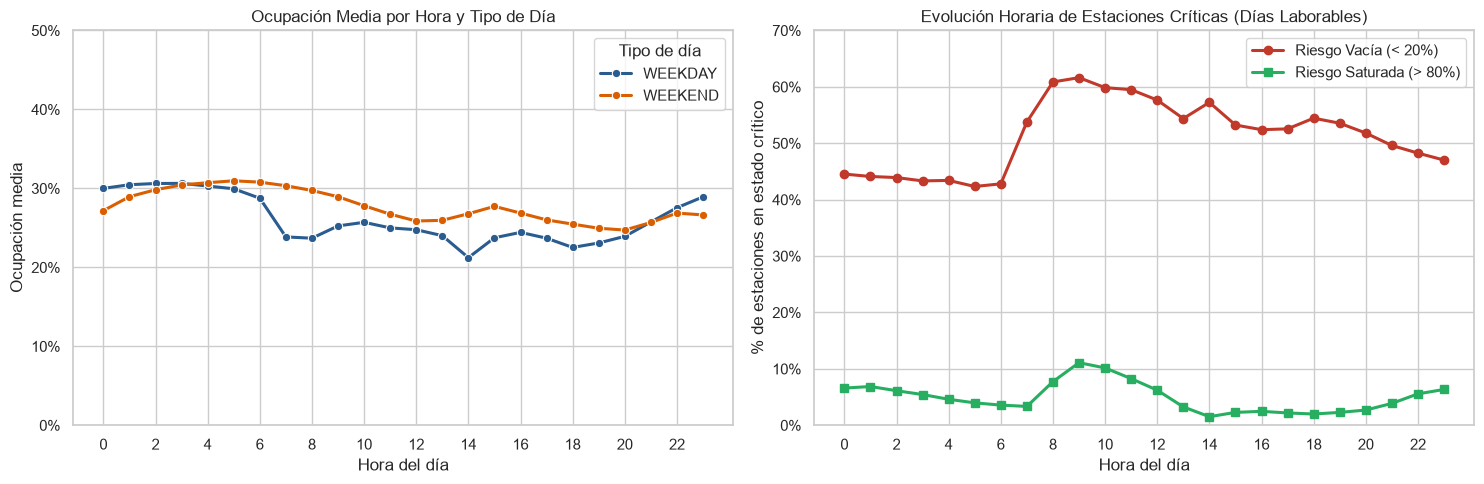

--- TOP 5 ESTACIONES QUE MÁS SE LLENAN DE 07:00 A 10:00 (POLOS DE DESTINO) ---


,hour,Occ 07:00,Occ 10:00,Variación
station_id,name,,,
73,45-Gran Vía. Paraninfo,0.1147,0.8686,0.7539
142,261-Campus. Betancourt,0.1949,0.9158,0.7209
48,47-S. Francisco: Universidad,0.1151,0.8237,0.7086
138,268- Gran Vía: Huerva,0.1647,0.8316,0.6669
135,133- Campus. Ada Byron,0.2616,0.9044,0.6427


--- TOP 5 ESTACIONES QUE MÁS SE VACÍAN DE 07:00 A 10:00 (ORIGEN RESIDENCIAL) ---


,hour,Occ 07:00,Occ 10:00,Variación
station_id,name,,,
16,55-M. Cadena: M. Asso,0.6813,0.0900,-0.5913
176,148-Felisa Galé: Oto,0.5858,0.0431,-0.5427
29,5-Macanaz,0.7251,0.2325,-0.4926
192,183- Corazón de Jesús: Padua,0.5284,0.0812,-0.4472
23,14-Delicias Salidas,0.6845,0.2646,-0.4199


--- ANÁLISIS DE SALTOS BRUSCOS (POSIBLE INTERVENCIÓN DE FURGONETA >= 8 BICIS EN 10 MIN) ---
Total pasos consecutivos de 10 min analizados : 497,628
Saltos bruscos detectados (|delta| >= 8 bicis) : 1,605 (0.32%)

--- CORRELACIÓN LINEAL (INERCIA) ENTRE OCUPACIÓN ACTUAL Y FUTURA ---
  - Actual vs +1h: 0.8025
  - Actual vs +2h: 0.6294
  - Actual vs +3h: 0.4861


In [6]:
# ==============================================================================
# 3.1. PATRÓN HORARIO: DÍAS LABORABLES VS. FINES DE SEMANA / FESTIVOS
# ==============================================================================
df_eda = df_model.copy()
df_eda["es_vacia"] = (df_eda["occupancy_pct"] < OCCUPANCY_LOW_THRESHOLD).astype(int)
df_eda["es_saturada"] = (df_eda["occupancy_pct"] > OCCUPANCY_HIGH_THRESHOLD).astype(int)

perfil_horario = (
    df_eda.groupby(["day_type_effective", "hour"], as_index=False)
    .agg(
        occ_media=("occupancy_pct", "mean"),
        pct_vacias=("es_vacia", "mean"),
        pct_saturadas=("es_saturada", "mean"),
    )
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Ocupación media horaria por tipo de día
sns.lineplot(
    data=perfil_horario,
    x="hour",
    y="occ_media",
    hue="day_type_effective",
    marker="o",
    linewidth=2.2,
    palette={"WEEKDAY": "#2b5c8f", "WEEKEND": "#d95f02"},
    ax=axes[0],
)
axes[0].set_title("Ocupación Media por Hora y Tipo de Día", fontsize=12)
axes[0].set_xlabel("Hora del día")
axes[0].set_ylabel("Ocupación media")
axes[0].set_xticks(range(0, 24, 2))
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[0].set_ylim(0, 0.50)
axes[0].legend(title="Tipo de día")

# Gráfico 2: % de estaciones críticas (<20% vs >80%) en días laborables
perfil_weekday = perfil_horario[perfil_horario["day_type_effective"] == "WEEKDAY"]
axes[1].plot(
    perfil_weekday["hour"],
    perfil_weekday["pct_vacias"],
    marker="o",
    linewidth=2.2,
    color="#c0392b",
    label="Riesgo Vacía (< 20%)",
)
axes[1].plot(
    perfil_weekday["hour"],
    perfil_weekday["pct_saturadas"],
    marker="s",
    linewidth=2.2,
    color="#27ae60",
    label="Riesgo Saturada (> 80%)",
)
axes[1].set_title("Evolución Horaria de Estaciones Críticas (Días Laborables)", fontsize=12)
axes[1].set_xlabel("Hora del día")
axes[1].set_ylabel("% de estaciones en estado crítico")
axes[1].set_xticks(range(0, 24, 2))
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].set_ylim(0, 0.70)
axes[1].legend()

plt.tight_layout()
plt.show()

# ==============================================================================
# 3.2. FLUJOS PENDULARES MATINALES (07:00H VS. 10:00H EN LABORABLES)
# ==============================================================================
occ_hora_estacion = (
    df_eda[df_eda["day_type_effective"] == "WEEKDAY"]
    .groupby(["station_id", "name", "hour"], as_index=False)["occupancy_pct"]
    .mean()
)

pivote_manana = occ_hora_estacion[occ_hora_estacion["hour"].isin([7, 10])].pivot(
    index=["station_id", "name"], columns="hour", values="occupancy_pct"
).dropna()

pivote_manana["delta_07_a_10"] = pivote_manana[10] - pivote_manana[7]

print("--- TOP 5 ESTACIONES QUE MÁS SE LLENAN DE 07:00 A 10:00 (POLOS DE DESTINO) ---")
display(
    pivote_manana.sort_values("delta_07_a_10", ascending=False)
    .head(5)
    .rename(columns={7: "Occ 07:00", 10: "Occ 10:00", "delta_07_a_10": "Variación"})
)

print("--- TOP 5 ESTACIONES QUE MÁS SE VACÍAN DE 07:00 A 10:00 (ORIGEN RESIDENCIAL) ---")
display(
    pivote_manana.sort_values("delta_07_a_10", ascending=True)
    .head(5)
    .rename(columns={7: "Occ 07:00", 10: "Occ 10:00", "delta_07_a_10": "Variación"})
)

# ==============================================================================
# 3.3. INERCIA TEMPORAL (AUTOCORRELACIÓN) Y DETECCIÓN DE SALTOS BRUSCOS
# ==============================================================================
df_eda = df_eda.sort_values(["station_id", "timestamp"]).reset_index(drop=True)
df_eda["dt_minutes"] = (
    df_eda.groupby("station_id")["timestamp"].diff().dt.total_seconds() / 60.0
)
df_eda["delta_bikes_10m"] = df_eda.groupby("station_id")["bikes_available"].diff()

# Filtramos solo pasos consecutivos reales de ~10 minutos (entre 8 y 12 min)
pasos_10m = df_eda[df_eda["dt_minutes"].between(8, 12)].copy()
saltos_bruscos = pasos_10m[pasos_10m["delta_bikes_10m"].abs() >= 8]

print("--- ANÁLISIS DE SALTOS BRUSCOS (POSIBLE INTERVENCIÓN DE FURGONETA >= 8 BICIS EN 10 MIN) ---")
print(f"Total pasos consecutivos de 10 min analizados : {len(pasos_10m):,}")
print(f"Saltos bruscos detectados (|delta| >= 8 bicis) : {len(saltos_bruscos):,} ({len(saltos_bruscos)/len(pasos_10m)*100:.2f}%)")

# Correlación de occupancy_pct actual con los horizontes futuros
correlaciones_horizonte = {
    "Actual vs +1h": df_eda[["occupancy_pct", "target_occ_1h"]].corr().iloc[0, 1],
    "Actual vs +2h": df_eda[["occupancy_pct", "target_occ_2h"]].corr().iloc[0, 1],
    "Actual vs +3h": df_eda[["occupancy_pct", "target_occ_3h"]].corr().iloc[0, 1],
}
print("\n--- CORRELACIÓN LINEAL (INERCIA) ENTRE OCUPACIÓN ACTUAL Y FUTURA ---")
for k, v in correlaciones_horizonte.items():
    print(f"  - {k}: {v:.4f}")

del df_eda, pasos_10m, saltos_bruscos

> ### 💡 Conclusiones del EDA Espacio-Temporal (Justificación de Predictors)
>
> 1. **Contraste entre días laborables y festivos (`WEEKDAY` vs. `WEEKEND`):**
>    * En días laborables, la ocupación media cae bruscamente entre las **07:00 y las 08:00** (pasando del ~29 % al ~24 %) y marca un valle a las **14:00 (~21 %)**, reflejando los desplazamientos masivos de entrada y salida de trabajo/estudio. En fines de semana y festivos, la curva es mucho más plana y mantiene una disponibilidad superior durante toda la mañana y el mediodía (~26 %–31 %).
>    * El porcentaje de estaciones en **riesgo de vaciado ($< 20\%$)** en laborables se dispara desde el ~43 % a las 06:00 hasta superar el **60 % entre las 08:00 y las 10:00** (pico del ~61,6 % a las 09:00), mientras que las estaciones **saturadas ($> 80\%$)** repuntan simultáneamente hasta el **~11 %** en esa misma franja punta.
>
> 2. **Confirmación empírica del flujo pendular (Barrios $\rightarrow$ Universidad / Centro):**
>    * **Polos de atracción (se llenan de 07:00 a 10:00):** Las estaciones que más crecen son nodos universitarios y céntricos como `45-Gran Vía. Paraninfo` (**+75,39 %**, pasando del 11,47 % al 86,86 %), `261-Campus. Betancourt` (**+72,09 %**, alcanzando el 91,58 %), `47-S. Francisco: Universidad` (**+70,86 %**), `268-Gran Vía: Huerva` (**+66,69 %**) y `133-Campus. Ada Byron` (**+64,27 %**).
>    * **Orígenes residenciales (se vacían de 07:00 a 10:00):** Las mayores caídas se producen en barrios residenciales como `55-M. Cadena: M. Asso` (**-59,13 %**, cayendo del 68,13 % al 9,00 %), `148-Felisa Galé: Oto` (**-54,27 %**, bajando al 4,31 %), `5-Macanaz` (**-49,26 %**), `183-Corazón de Jesús: Padua` (**-44,72 %**) y `14-Delicias Salidas` (**-41,99 %**).
>
> 3. **Inercia temporal y huella de las 6 furgonetas:**
>    * La correlación entre la ocupación actual y la futura es muy alta a corto plazo (**0,8025** a $+1\text{ h}$), moderada a medio plazo (**0,6294** a $+2\text{ h}$) y decae a **0,4861** a $+3\text{ h}$. Esto demuestra que para $+1\text{ h}$ basta con capturar bien la inercia reciente, pero para $+2\text{ h}$ y $+3\text{ h}$ el modelo necesita variables espaciales y de calendario para anticipar el cambio de ciclo pendular.
>    * Sobre **497.628 pasos consecutivos** de 10 minutos, se detectan **1.605 saltos bruscos** ($|\Delta \text{bicis}| \ge 8$ en 10 min, el **0,32 %** de las capturas), que actúan como indicador (*proxy*) de intervenciones de carga/descarga realizadas por las furgonetas de logística.

---
## 4. Feature Engineering (Ingeniería de Características)

En esta sección transformamos el dataset alineado en una matriz de predictores espacio-temporales libre de fuga de información (*data leakage*), encapsulada en funciones modulares listas para migrar a `src/modeling/features.py`.

### Bloques de variables construidas
1. **Inercia intradía, velocidad y volatilidad:** Retardos exactos de ocupación a $-10\text{ min}$, $-30\text{ min}$ y $-1\text{ h}$ (alineados mediante `merge_asof` hacia atrás con tolerancia estricta para no saltar huecos de captura), junto con la velocidad de cambio ($\Delta \text{occ}_{30\text{m}}$, $\Delta \text{occ}_{1\text{h}}$) y la desviación estándar móvil de la última hora.
2. **Memoria diaria y semanal ($-24\text{ h}$ y $-7\text{ días}$):** Ocupación observada en la misma estación exactamente 24 horas antes y 7 días antes (mismo día de la semana y franja horaria). Los algoritmos basados en árboles gestionan de forma nativa los `NaN` de los primeros días, permitiendo que el código escale sin cambios al superar el mes de histórico.
3. **Perfil basal causal propio (`causal_hist_occ_mean`):** Dado que `occupancy_avg` de la API solo está disponible tras su descarga, calculamos de forma estrictamente causal la media histórica de cada estación por `(day_type_effective, hour)` acumulando únicamente jornadas anteriores ($< \text{fecha actual}$), y medimos la desviación en tiempo real (`occ_diff_vs_hist_mean`).
4. **Calendario y codificación cíclica ($t$ y $t + h$):** Representación trigonométrica ($\sin/\cos$) de la hora actual, del día de la semana y de la hora objetivo futura ($t + 1\text{ h}, +2\text{ h}, +3\text{ h}$), combinada con `day_type_effective` e `is_holiday`.
5. **Identidad espacial, capacidad efectiva y *proxy* de furgonetas:** Coordenadas (`latitude`, `longitude`), `capacity`, unidades inutilizadas por avería (`disabled_units`), `station_id` como categoría e indicador de salto logístico brusco ($|\Delta \text{bicis}_{10\text{m}}| \ge 8$) en la última hora.

In [7]:
# ==============================================================================
# 4.1. FUNCIONES DE FEATURE ENGINEERING (FUTURO src/modeling/features.py)
# ==============================================================================
def add_lag_and_rolling_features(df: pd.DataFrame) -> pd.DataFrame:
    """Calcula retardos temporales estrictos, velocidad, volatilidad y proxy de furgonetas."""
    out = df.sort_values(["station_id", "timestamp"]).reset_index(drop=True).copy()

    # Tabla de referencia histórica observada ordenada globalmente por timestamp para merge_asof
    ref = (
        out[["station_id", "timestamp", "occupancy_pct"]]
        .sort_values("timestamp")
        .reset_index(drop=True)
        .copy()
    )

    # 1. Retardos exactos mediante merge_asof hacia atrás con tolerancia controlada
    lag_specs = [
        ("occ_lag_10m", pd.Timedelta(minutes=10), pd.Timedelta(minutes=5)),
        ("occ_lag_30m", pd.Timedelta(minutes=30), pd.Timedelta(minutes=10)),
        ("occ_lag_1h", pd.Timedelta(hours=1), pd.Timedelta(minutes=10)),
        ("occ_lag_24h", pd.Timedelta(hours=24), pd.Timedelta(minutes=15)),
        ("occ_lag_7d", pd.Timedelta(days=7), pd.Timedelta(minutes=15)),
    ]

    for col_name, offset, tol in lag_specs:
        out["_lookup_ts"] = out["timestamp"] - offset
        out = pd.merge_asof(
            out.sort_values("_lookup_ts"),
            ref.rename(
                columns={"timestamp": "_ref_ts", "occupancy_pct": col_name}
            ),
            left_on="_lookup_ts",
            right_on="_ref_ts",
            by="station_id",
            direction="nearest",
            tolerance=tol,
        )
        out.drop(columns=["_lookup_ts", "_ref_ts"], inplace=True)

    # Reordenamos por estación y timestamp para cálculos secuenciales
    out = out.sort_values(["station_id", "timestamp"]).reset_index(drop=True)

    # 2. Velocidad de cambio (tendencia reciente)
    out["delta_occ_30m"] = out["occupancy_pct"] - out["occ_lag_30m"]
    out["delta_occ_1h"] = out["occupancy_pct"] - out["occ_lag_1h"]

    # 3. Volatilidad reciente (desviación típica móvil de las últimas 6 capturas por estación)
    out["rolling_std_1h"] = (
        out.groupby("station_id")["occupancy_pct"]
        .transform(lambda s: s.rolling(window=6, min_periods=2).std())
        .fillna(0.0)
    )

    # 4. Proxy de intervención logística de furgonetas (saltos bruscos en ~10 min)
    dt_min = out.groupby("station_id")["timestamp"].diff().dt.total_seconds() / 60.0
    delta_bikes = out.groupby("station_id")["bikes_available"].diff()

    is_step_10m = dt_min.between(8, 12)
    out["delta_bikes_10m"] = np.where(is_step_10m, delta_bikes, 0.0)
    out["is_logistic_jump"] = (out["delta_bikes_10m"].abs() >= 8).astype(int)
    out["logistic_jumps_last_1h"] = (
        out.groupby("station_id")["is_logistic_jump"]
        .transform(lambda s: s.rolling(window=6, min_periods=1).sum())
    )

    return out


def add_causal_historical_profile(df: pd.DataFrame) -> pd.DataFrame:
    """Calcula la media histórica causal por (estación, tipo de día, hora) usando solo días previos."""
    out = df.copy()
    out["_date_only"] = out["timestamp"].dt.floor("D")

    # Agregación diaria por estación, tipo de día efectivo y hora
    daily_slot = (
        out.groupby(["station_id", "day_type_effective", "hour", "_date_only"], as_index=False)
        .agg(
            _day_occ_sum=("occupancy_pct", "sum"),
            _day_occ_cnt=("occupancy_pct", "count"),
        )
        .sort_values(["station_id", "day_type_effective", "hour", "_date_only"])
    )

    # Acumulado estrictamente anterior al día actual (shift(1) sobre jornadas)
    grp_cols = ["station_id", "day_type_effective", "hour"]
    daily_slot["_cum_sum_prev"] = (
        daily_slot.groupby(grp_cols)["_day_occ_sum"].cumsum() - daily_slot["_day_occ_sum"]
    )
    daily_slot["_cum_cnt_prev"] = (
        daily_slot.groupby(grp_cols)["_day_occ_cnt"].cumsum() - daily_slot["_day_occ_cnt"]
    )

    daily_slot["causal_hist_occ_mean"] = np.where(
        daily_slot["_cum_cnt_prev"] > 0,
        daily_slot["_cum_sum_prev"] / daily_slot["_cum_cnt_prev"],
        np.nan,
    )

    out = out.merge(
        daily_slot[grp_cols + ["_date_only", "causal_hist_occ_mean"]],
        on=grp_cols + ["_date_only"],
        how="left",
        validate="m:1",
    )

    out["occ_diff_vs_hist_mean"] = out["occupancy_pct"] - out["causal_hist_occ_mean"]
    out.drop(columns=["_date_only"], inplace=True)

    return out


def add_calendar_and_horizon_features(
    df: pd.DataFrame,
    horizons: list[int] = [1, 2, 3],
    df_cal: pd.DataFrame | None = None,
) -> pd.DataFrame:
    """Genera variables de calendario y codificación cíclica para t y cada horizonte t+h."""
    out = df.copy()

    # Codificación cíclica del instante actual t
    out["hour_sin"] = np.sin(2 * np.pi * out["hour"] / 24.0)
    out["hour_cos"] = np.cos(2 * np.pi * out["hour"] / 24.0)

    dow = out["timestamp"].dt.dayofweek
    out["dow_sin"] = np.sin(2 * np.pi * dow / 7.0)
    out["dow_cos"] = np.cos(2 * np.pi * dow / 7.0)
    out["is_weekend_flag"] = (out["day_type_effective"] == "WEEKEND").astype(int)

    # Mapa de días efectivos (incluyendo festivos locales/nacionales) si se aporta dim_calendar
    weekend_date_keys = None
    if df_cal is not None and {"date_key", "day_type_effective"}.issubset(df_cal.columns):
        weekend_date_keys = set(
            df_cal.loc[df_cal["day_type_effective"] == "WEEKEND", "date_key"].astype(int)
        )

    # Variables cíclicas específicas de la hora objetivo t + h
    for h in horizons:
        future_ts = out["timestamp"] + pd.Timedelta(hours=h)
        f_hour = future_ts.dt.hour
        f_dow = future_ts.dt.dayofweek

        out[f"target_hour_sin_{h}h"] = np.sin(2 * np.pi * f_hour / 24.0)
        out[f"target_hour_cos_{h}h"] = np.cos(2 * np.pi * f_hour / 24.0)

        if weekend_date_keys is not None:
            f_date_key = future_ts.dt.strftime("%Y%m%d").astype(int)
            out[f"target_is_weekend_{h}h"] = np.where(
                f_date_key.isin(weekend_date_keys) | (f_dow >= 5), 1, 0
            )
        else:
            out[f"target_is_weekend_{h}h"] = (f_dow >= 5).astype(int)

    return out


def build_feature_matrix(
    df: pd.DataFrame,
    horizons: list[int] = [1, 2, 3],
    df_cal: pd.DataFrame | None = None,
) -> pd.DataFrame:
    """Pipeline completo de Feature Engineering listo para entrenamiento e inferencia."""
    df_feat = add_lag_and_rolling_features(df)
    df_feat = add_causal_historical_profile(df_feat)
    df_feat = add_calendar_and_horizon_features(df_feat, horizons=horizons, df_cal=df_cal)

    # Identificador de estación como categórica nativa para modelos de árboles
    df_feat["station_id_cat"] = df_feat["station_id"].astype("category")
    return df_feat


# Ejecución del pipeline de Feature Engineering sobre df_model
df_features = build_feature_matrix(df_model, horizons=HORIZONS_HOURS, df_cal=df_calendar)

# Listado de columnas candidatas a predictores (features)
BASE_FEATURES = [
    # Estado actual y capacidad física
    "occupancy_pct",
    "bikes_available",
    "anchors_free",
    "capacity",
    "disabled_units",
    # Ubicación e identidad espacial
    "station_id_cat",
    "latitude",
    "longitude",
    # Retardos, velocidad y volatilidad
    "occ_lag_10m",
    "occ_lag_30m",
    "occ_lag_1h",
    "occ_lag_24h",
    "occ_lag_7d",
    "delta_occ_30m",
    "delta_occ_1h",
    "rolling_std_1h",
    # Perfil basal causal
    "causal_hist_occ_mean",
    "occ_diff_vs_hist_mean",
    # Huella logística (furgonetas)
    "delta_bikes_10m",
    "is_logistic_jump",
    "logistic_jumps_last_1h",
    # Calendario actual
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "is_weekend_flag",
    "is_holiday",
]

# Auditoría de las nuevas features creadas
nuevas_cols = [c for c in BASE_FEATURES if c not in df_model.columns]
resumen_fe = pd.DataFrame({
    "Feature": nuevas_cols,
    "Tipo": [str(df_features[c].dtype) for c in nuevas_cols],
    "% Nulos": [(df_features[c].isna().mean() * 100).round(2) for c in nuevas_cols],
    "Media": [
        round(df_features[c].mean(), 4) if pd.api.types.is_numeric_dtype(df_features[c]) else np.nan
        for c in nuevas_cols
    ],
    "Std": [
        round(df_features[c].std(), 4) if pd.api.types.is_numeric_dtype(df_features[c]) else np.nan
        for c in nuevas_cols
    ],
})

print(f"Dataset tras Feature Engineering: {df_features.shape[0]:,} filas x {df_features.shape[1]} columnas")
print(f"Total predictores base definidos: {len(BASE_FEATURES)} (+3 específicos por horizonte h)")
print("\n--- AUDITORÍA DE NUEVAS VARIABLES CREADAS ---")
display(resumen_fe)

Dataset tras Feature Engineering: 540,960 filas x 61 columnas
Total predictores base definidos: 27 (+3 específicos por horizonte h)

--- AUDITORÍA DE NUEVAS VARIABLES CREADAS ---


,Feature,Tipo,% Nulos,Media,Std
0,station_id_cat,category,0.0000,NaN,NaN
1,occ_lag_10m,float64,1.1700,0.2660,0.2555
2,occ_lag_30m,float64,0.8700,0.2659,0.2556
3,occ_lag_1h,float64,1.0700,0.2660,0.2556
4,occ_lag_24h,float64,7.3000,0.2647,0.2561
5,occ_lag_7d,float64,50.8700,0.2595,0.2583
6,delta_occ_30m,float64,0.8700,0.0000,0.1155
7,delta_occ_1h,float64,1.0700,0.0000,0.1606
8,rolling_std_1h,float64,0.0000,0.0512,0.0522
9,causal_hist_occ_mean,float64,12.4000,0.2621,0.2044


> ### 💡 Conclusiones de la Ingeniería de Características (Feature Engineering)
>
> 1. **Dimensión final y modularidad:**
>    * La matriz resultante conserva intactas las **540.960 filas** originales y amplía el espacio de representación a **61 columnas**, definiendo **27 predictores base** más **3 variables cíclicas específicas por cada horizonte objetivo** ($h \in \{1\text{ h}, 2\text{ h}, 3\text{ h}\}$, totalizando **30 predictores** por modelo).
>    * Toda la lógica está encapsulada en funciones puras (`add_lag_and_rolling_features`, `add_causal_historical_profile`, `add_calendar_and_horizon_features` y `build_feature_matrix`) listas para migrar directamente a `src/modeling/features.py`.
>
> 2. **Cobertura de retardos y escalabilidad a $>1\text{ mes}$ de histórico:**
>    * **Inercia intradía (`occ_lag_10m`, `occ_lag_30m`, `occ_lag_1h`):** Presentan una cobertura prácticamente completa (solo entre un **0,87 % y un 1,17 %** de nulos derivados de los primeros instantes de la serie o microcortes de captura), con desviaciones de velocidad coherentes ($\sigma = 0,1155$ a 30 min y $\sigma = 0,1606$ a 1 h).
>    * **Memoria diaria (`occ_lag_24h`):** Alcanza un **92,70 %** de cobertura (**7,30 %** de nulos correspondientes al primer día sin jornada previa), aportando una referencia directa del mismo tramo horario del día anterior.
>    * **Memoria semanal (`occ_lag_7d`):** En esta ventana inicial de 16 días presenta un **50,87 %** de nulos (los primeros 7 días completos), porcentaje que se reducirá automáticamente por debajo del 20–25 % al incorporar más de un mes de histórico en la entrega final sin modificar el código.
>
> 3. **Perfil basal causal y detección de intervenciones logísticas:**
>    * El perfil histórico propio (`causal_hist_occ_mean` y `occ_diff_vs_hist_mean`) cubre el **87,60 %** del dataset (**12,40 %** de nulos correspondientes a la primera aparición de cada combinación estación-tipo de día-hora) sin ningún riesgo de fuga de datos futuros.
>    * El *proxy* de actividad de furgonetas (`is_logistic_jump`) marca exactamente el **0,30 %** de los registros con movimientos bruscos ($\ge 8$ bicicletas en 10 min) y `logistic_jumps_last_1h` acumula la actividad logística de la última hora con **0 %** de valores nulos.

---
## 5. Estrategia de Partición Temporal (Train / Validación / Test)

En problemas de series temporales multi-estación, una partición aleatoria (*shuffle*) introduce una **fuga temporal crítica (*temporal data leakage*)**: el algoritmo aprendería patrones contemporáneos de estaciones vecinas en el mismo instante, inflando artificialmente las métricas respecto a su comportamiento real en producción.

### Diseño de la partición cronológica con embargo de seguridad
1. **Alineación común multi-horizonte:** Conservamos únicamente los registros donde los tres objetivos futuros (`target_occ_1h`, `target_occ_2h` y `target_occ_3h`) son válidos simultáneamente, garantizando que los modelos a $+1\text{ h}$, $+2\text{ h}$ y $+3\text{ h}$ se entrenen y evalúen sobre exactamente los mismos instantes.
2. **Corte cronológico global (`70 % Train / 15 % Validación / 15 % Test`):** Ordenamos el eje temporal de forma estricta y dividimos por marcas de tiempo completas (`timestamp`), asegurando que las **276 estaciones** pasen juntas de entrenamiento a validación y a prueba sin mezclar observaciones simultáneas.
3. **Ventana de embargo de 3 horas (`max(HORIZONS_HOURS)`):** Aplicamos una separación de seguridad de $3\text{ horas}$ entre *Train* y *Validación*, y entre *Validación* y *Test*. De este modo, el horizonte objetivo más lejano ($t + 3\text{ h}$) de las últimas filas de entrenamiento nunca invade el periodo de validación, ni el de validación invade el conjunto de test.
4. **Roles de cada partición:**
   * **Train (70 %):** Ajuste de parámetros de los modelos y cálculo de transformadores de preprocesado.
   * **Validación (15 %):** Selección de algoritmos y optimización bayesiana de hiperparámetros con Optuna.
   * **Test (15 %):** Evaluación final ciega (métricas de regresión, alertas operativas, explicabilidad SHAP y simulación de rutas).

--- AUDITORÍA DE PARTICIONES TEMPORALES (CON EMBARGO DE 3H) ---


,Partición,Registros,% Útil,Estaciones,Inicio,Fin,Media occ actual,Media target +1h,% Fin de semana
0,Train (70%),366528,69.0600,276,2026-11-02 10:35:56+01:00,2026-11-11 12:59:56+01:00,0.2626,0.2626,22.2900
1,Validación (15%),74244,13.9900,276,2026-11-11 16:19:57+01:00,2026-11-13 14:00:00+01:00,0.2689,0.2670,0.0000
2,Test (15%),79488,14.9800,276,2026-11-13 17:19:59+01:00,2026-11-15 16:47:57+01:00,0.2820,0.2821,85.4200


Registros descartados en ventanas de embargo (2 x 3h): 10,488
Predictores totales por horizonte (ej. h=1h)         : 30 variables


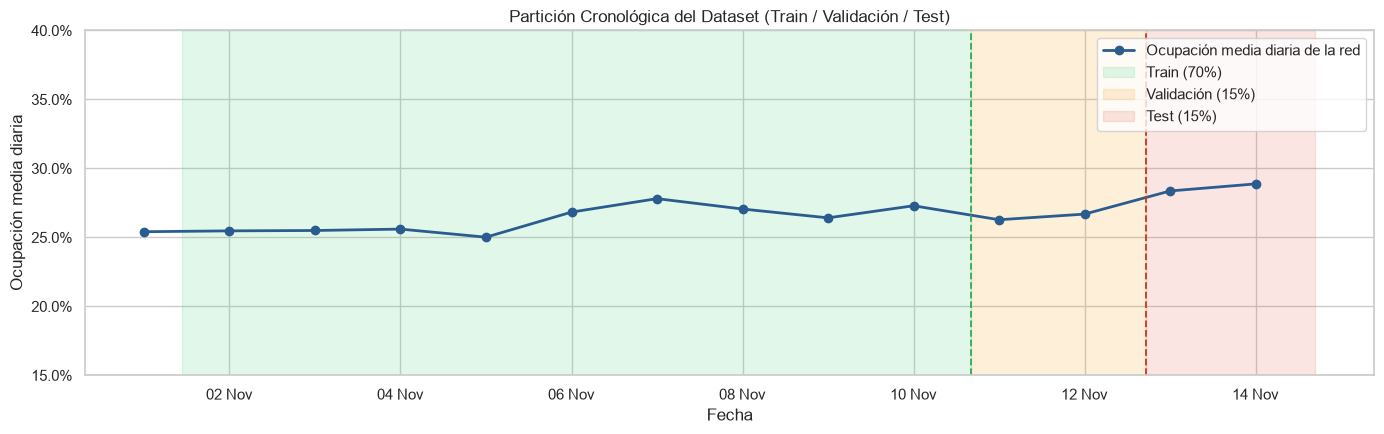

In [8]:
# ==============================================================================
# 5.1. PARTICIÓN TEMPORAL ESTRICTA CON EMBARGO (TRAIN / VALIDACIÓN / TEST)
# ==============================================================================
TARGET_COLS = [f"target_occ_{h}h" for h in HORIZONS_HOURS]


def get_features_for_horizon(horizon_h: int) -> list[str]:
    """Devuelve la lista ordenada de predictores para un horizonte h concreto."""
    horizon_specific = [
        f"target_hour_sin_{horizon_h}h",
        f"target_hour_cos_{horizon_h}h",
        f"target_is_weekend_{horizon_h}h",
    ]
    return BASE_FEATURES + horizon_specific


# 1. Filtramos observaciones con los 3 horizontes válidos y ordenamos cronológicamente
df_clean = (
    df_features.dropna(subset=TARGET_COLS)
    .sort_values(["timestamp", "station_id"])
    .reset_index(drop=True)
    .copy()
)

# 2. Definición de puntos de corte sobre marcas temporales únicas (70% / 15% / 15%)
unique_ts = np.sort(df_clean["timestamp"].unique())
n_ts = len(unique_ts)

embargo = pd.Timedelta(hours=max(HORIZONS_HOURS))
train_cutoff_ts = pd.Timestamp(unique_ts[int(n_ts * 0.70)])
val_cutoff_ts = pd.Timestamp(unique_ts[int(n_ts * 0.85)])

mask_train = df_clean["timestamp"] <= (train_cutoff_ts - embargo)
mask_val = (df_clean["timestamp"] > train_cutoff_ts) & (
    df_clean["timestamp"] <= (val_cutoff_ts - embargo)
)
mask_test = df_clean["timestamp"] > val_cutoff_ts

df_train = df_clean[mask_train].reset_index(drop=True)
df_val = df_clean[mask_val].reset_index(drop=True)
df_test = df_clean[mask_test].reset_index(drop=True)

# 3. Tabla resumen de auditoría de las particiones
resumen_splits = []
for nombre, subset in [("Train (70%)", df_train), ("Validación (15%)", df_val), ("Test (15%)", df_test)]:
    resumen_splits.append({
        "Partición": nombre,
        "Registros": len(subset),
        "% Útil": round(len(subset) / len(df_clean) * 100, 2),
        "Estaciones": subset["station_id"].nunique(),
        "Inicio": subset["timestamp"].min(),
        "Fin": subset["timestamp"].max(),
        "Media occ actual": round(subset["occupancy_pct"].mean(), 4),
        "Media target +1h": round(subset["target_occ_1h"].mean(), 4),
        "% Fin de semana": round(subset["is_weekend_flag"].mean() * 100, 2),
    })

print("--- AUDITORÍA DE PARTICIONES TEMPORALES (CON EMBARGO DE 3H) ---")
display(pd.DataFrame(resumen_splits))

descartados_embargo = len(df_clean) - (len(df_train) + len(df_val) + len(df_test))
print(f"Registros descartados en ventanas de embargo (2 x 3h): {descartados_embargo:,}")
print(f"Predictores totales por horizonte (ej. h=1h)         : {len(get_features_for_horizon(1))} variables")

# 4. Visualización de la evolución diaria y las fronteras de partición
serie_diaria = (
    df_clean.assign(fecha=df_clean["timestamp"].dt.floor("D"))
    .groupby("fecha", as_index=False)
    .agg(occ_media=("occupancy_pct", "mean"), registros=("station_id", "count"))
)

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(
    serie_diaria["fecha"],
    serie_diaria["occ_media"],
    marker="o",
    linewidth=2,
    color="#2b5c8f",
    label="Ocupación media diaria de la red",
)

# Sombreado de cada partición temporal
ax.axvspan(df_train["timestamp"].min(), train_cutoff_ts, color="#2ecc71", alpha=0.14, label="Train (70%)")
ax.axvspan(train_cutoff_ts, val_cutoff_ts, color="#f39c12", alpha=0.16, label="Validación (15%)")
ax.axvspan(val_cutoff_ts, df_test["timestamp"].max(), color="#e74c3c", alpha=0.14, label="Test (15%)")

ax.axvline(train_cutoff_ts, color="#27ae60", linestyle="--", linewidth=1.3)
ax.axvline(val_cutoff_ts, color="#c0392b", linestyle="--", linewidth=1.3)

ax.set_title("Partición Cronológica del Dataset (Train / Validación / Test)", fontsize=12)
ax.set_xlabel("Fecha")
ax.set_ylabel("Ocupación media diaria")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylim(0.15, 0.40)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

> ### 💡 Diagnóstico de la Partición Cronológica (Train / Validación / Test)
>
> * **Aislamiento temporal estricto y embargo de seguridad:** Sobre los **530.748 registros** con los tres horizontes válidos, el corte cronológico retiene **366.528 filas en Train (69,06 %)**, **74.244 en Validación (13,99 %)** y **79.488 en Test (14,98 %)**, descartando exactamente **10.488 registros** en las dos fronteras de embargo de $3\text{ horas}$ para garantizar cero solapamiento entre las etiquetas futuras de una partición y los predictores de la siguiente.
> * **Estabilidad de la ocupación media entre subconjuntos:** La ocupación media actual se mantiene muy homogénea en toda la cronología (**0,2626** en *Train*, **0,2689** en *Validación* y **0,2820** en *Test*), con las **276 estaciones** representadas íntegramente en los tres bloques.
> * **Lectura operativa de la composición semanal (16 días vs. $>1\text{ mes}$):** En esta ventana inicial de 16 días, el bloque de *Validación* (`11 nov` a `13 nov`) recae íntegramente en días laborables (**0,00 %** de fin de semana), mientras que el bloque de *Test* (`13 nov` tarde a `15 nov` tarde) concentra un **85,42 %** de fin de semana. Esto pone a prueba la capacidad de generalización del modelo ante cambios de régimen y refuerza la importancia de ampliar el histórico por encima de los 30 días en la entrega final para que tanto *Validación* como *Test* abarquen semanas completas equilibradas.

---
## 6. Preprocesado y Tubería de Transformación

Para evitar cualquier fuga de información (*data leakage*), todos los transformadores de preprocesado se ajustan (`fit`) **exclusivamente sobre `df_train`** y se aplican (`transform`) sobre `df_val` y `df_test`.

Dado que vamos a comparar familias de algoritmos con requisitos distintos frente a valores nulos, escalas y variables categóricas, definimos dos tuberías modulares (listas para migrar a `src/modeling/`):

1. **Preprocesador para Modelos Lineales (`build_linear_preprocessor`):**
   * **Variables numéricas:** Imputación por mediana (`SimpleImputer(strategy="median")`) para cubrir los `NaN` iniciales de los retardos largos (`occ_lag_24h`, `occ_lag_7d`, `causal_hist_occ_mean`) seguida de estandarización z-score (`StandardScaler()`).
   * **Variables categóricas (`station_id_cat`):** Codificación binaria mediante `OneHotEncoder(handle_unknown="ignore", sparse_output=False)` para que el modelo lineal estime un intercepto específico por estación sin asumir un orden numérico artificial entre identificadores.
2. **Preprocesador para Modelos Basados en Árboles (`prepare_tree_matrices`):**
   * **Conservación nativa de `NaN` y escalas:** Los algoritmos de *Gradient Boosting* (LightGBM y XGBoost) son invariantes al escalado monótono y gestionan de forma óptima los `NaN` estructurales de los primeros días sin distorsionar las distribuciones con imputaciones artificiales.
   * **Tratamiento de `station_id_cat`:** Se mantiene como tipo `category` de Pandas con niveles alineados entre *Train*, *Validación* y *Test* (y con su código entero como respaldo para Random Forest).

In [9]:
# ==============================================================================
# 6.1. TUBERÍAS DE PREPROCESADO (SIN FUGA DE DATOS)
# ==============================================================================
CATEGORICAL_COLS = ["station_id_cat"]


def build_linear_preprocessor(feature_cols: list[str]) -> ColumnTransformer:
    """Construye un ColumnTransformer con imputación y escalado para modelos lineales."""
    num_cols = [c for c in feature_cols if c not in CATEGORICAL_COLS]
    cat_cols = [c for c in feature_cols if c in CATEGORICAL_COLS]

    numeric_pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]
    )

    categorical_pipeline = Pipeline(
        steps=[
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )

    return ColumnTransformer(
        transformers=[
            ("num", numeric_pipeline, num_cols),
            ("cat", categorical_pipeline, cat_cols),
        ],
        remainder="drop",
    )


def prepare_tree_datasets(
    train_df: pd.DataFrame,
    val_df: pd.DataFrame,
    test_df: pd.DataFrame,
    feature_cols: list[str],
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Alinea categorías y tipos numéricos para modelos basados en árboles."""
    X_tr = train_df[feature_cols].copy()
    X_va = val_df[feature_cols].copy()
    X_te = test_df[feature_cols].copy()

    # Aseguramos las mismas categorías aprendidas en Train para evitar desajustes
    train_categories = X_tr["station_id_cat"].cat.categories
    for df_part in (X_tr, X_va, X_te):
        df_part["station_id_cat"] = pd.Categorical(
            df_part["station_id_cat"], categories=train_categories
        )

    return X_tr, X_va, X_te


# Verificación de dimensiones sobre el horizonte táctico h = 1h
features_1h = get_features_for_horizon(1)

# 1. Prueba del preprocesador lineal (fit solo en Train)
linear_prep_demo = build_linear_preprocessor(features_1h)
X_train_lin_1h = linear_prep_demo.fit_transform(df_train[features_1h])
X_val_lin_1h = linear_prep_demo.transform(df_val[features_1h])
X_test_lin_1h = linear_prep_demo.transform(df_test[features_1h])

# 2. Prueba de matrices para árboles
X_train_tree_1h, X_val_tree_1h, X_test_tree_1h = prepare_tree_datasets(
    df_train, df_val, df_test, features_1h
)

print("--- VERIFICACIÓN DEL PREPROCESADO (HORIZONTE h = +1H) ---")
print(f"Matrices Lineales (con One-Hot de 276 estaciones):")
print(f"  - X_train_lin : {X_train_lin_1h.shape} | Nulos restantes: {np.isnan(X_train_lin_1h).sum()}")
print(f"  - X_val_lin   : {X_val_lin_1h.shape} | Nulos restantes: {np.isnan(X_val_lin_1h).sum()}")
print(f"  - X_test_lin  : {X_test_lin_1h.shape} | Nulos restantes: {np.isnan(X_test_lin_1h).sum()}")

print(f"\nMatrices Árboles (categoría nativa + NaN estructurales preservados):")
print(f"  - X_train_tree: {X_train_tree_1h.shape}")
print(f"  - X_val_tree  : {X_val_tree_1h.shape}")
print(f"  - X_test_tree : {X_test_tree_1h.shape}")

# Liberamos objetos temporales de demostración
del linear_prep_demo, X_train_lin_1h, X_val_lin_1h, X_test_lin_1h, X_train_tree_1h, X_val_tree_1h, X_test_tree_1h

--- VERIFICACIÓN DEL PREPROCESADO (HORIZONTE h = +1H) ---
Matrices Lineales (con One-Hot de 276 estaciones):
  - X_train_lin : (366528, 305) | Nulos restantes: 0
  - X_val_lin   : (74244, 305) | Nulos restantes: 0
  - X_test_lin  : (79488, 305) | Nulos restantes: 0

Matrices Árboles (categoría nativa + NaN estructurales preservados):
  - X_train_tree: (366528, 30)
  - X_val_tree  : (74244, 30)
  - X_test_tree : (79488, 30)


> ### 💡 Diagnóstico de las Tuberías de Preprocesado
>
> * **Rama lineal libre de nulos y escalada (`305` dimensiones):** Tras ajustar el `ColumnTransformer` exclusivamente sobre *Train*, las matrices resultantes quedan con **0 valores nulos** en los tres subconjuntos (`366.528 x 305` en *Train*, `74.244 x 305` en *Validación* y `79.488 x 305` en *Test*), incorporando la codificación *One-Hot* de las 276 estaciones junto con la imputación por mediana y estandarización z-score.
> * **Rama compacta para modelos de árboles (`30` dimensiones):** Conserva la estructura tabular original (`366.528 x 30`, `74.244 x 30` y `79.488 x 30`) preservando los `NaN` estructurales de los primeros días y los niveles categóricos alineados de `station_id_cat`, evitando la explosión dimensional innecesaria en algoritmos basados en particiones.

---
## 7. Modelos Baseline (Referencias Mínimas a Batir)

Antes de entrenar algoritmos complejos de aprendizaje automático, establecemos **tres referencias base (*baselines*)** sobre el conjunto de **Validación (`df_val`)** para los tres horizontes tácticos ($h \in \{1\text{ h}, 2\text{ h}, 3\text{ h}\}$), manteniendo el conjunto de *Test* bloqueado hasta la evaluación ciega final:

1. **Baseline 1 — Persistencia (*Naive*):** Asume que la ocupación futura en $t + h$ será idéntica a la ocupación observada actualmente en $t$ ($\hat{y}_{t+h} = y_t$). Mide cuánto aporta la pura inercia instantánea de la red.
2. **Baseline 2 — Perfil Histórico Causal (`causal_hist_occ_mean`):** Estima la ocupación futura usando la media histórica acumulada de cada estación por `(day_type_effective, hour)` (con respaldo de la media global de *Train* en combinaciones aún sin histórico previo). Representa una planificación estática basada únicamente en patrones horarios.
3. **Baseline 3 — Regresión Lineal Regularizada (`Ridge`):** Primer modelo paramétrico entrenado sobre las 305 variables preprocesadas (inercia, tendencias, calendario cíclico y efectos fijos por estación).

### Métricas de evaluación (técnicas + operativas)
* **Métricas de regresión:** **MAE** (error absoluto medio en puntos de ocupación, interpretable directamente en porcentaje), **RMSE** (penaliza errores grandes en horas punta) y **$R^2$**.
* **Métricas operativas derivadas:** Evaluamos si el valor continuo predicho $\hat{y}_{t+h}$ clasifica correctamente las estaciones que entrarán en **riesgo de vaciado ($< 20\%$)** o **saturación ($> 80\%$)** mediante **Precision**, **Recall** y **F1-Score operativo**, que son los eventos que disparan la intervención de las 6 furgonetas.

In [10]:
# ==============================================================================
# 7.1. FUNCIÓN DE EVALUACIÓN UNIFICADA Y MODELOS BASELINE (SOBRE VALIDACIÓN)
# ==============================================================================
comparador_val = pd.DataFrame(
    columns=[
        "Modelo",
        "Horizonte",
        "MAE",
        "RMSE",
        "R2",
        "F1 Vacía (<20%)",
        "Recall Vacía",
        "F1 Saturada (>80%)",
    ]
)


def evaluar_prediccion(
    nombre_modelo: str,
    horizonte_h: int,
    y_real: np.ndarray | pd.Series,
    y_pred: np.ndarray,
    registrar: bool = True,
) -> dict:
    """Calcula métricas de regresión y de detección operativa de estados críticos."""
    y_real_arr = np.asarray(y_real, dtype=float)
    y_pred_clip = np.clip(np.asarray(y_pred, dtype=float), 0.0, 1.0)

    mae = mean_absolute_error(y_real_arr, y_pred_clip)
    rmse = root_mean_squared_error(y_real_arr, y_pred_clip)
    r2 = r2_score(y_real_arr, y_pred_clip)

    # Eventos operativos que activan las rutas de rebalanceo
    real_vacia = (y_real_arr < OCCUPANCY_LOW_THRESHOLD).astype(int)
    pred_vacia = (y_pred_clip < OCCUPANCY_LOW_THRESHOLD).astype(int)

    real_sat = (y_real_arr > OCCUPANCY_HIGH_THRESHOLD).astype(int)
    pred_sat = (y_pred_clip > OCCUPANCY_HIGH_THRESHOLD).astype(int)

    f1_vacia = f1_score(real_vacia, pred_vacia, zero_division=0)
    rec_vacia = recall_score(real_vacia, pred_vacia, zero_division=0)
    f1_sat = f1_score(real_sat, pred_sat, zero_division=0)

    fila = {
        "Modelo": nombre_modelo,
        "Horizonte": f"+{horizonte_h}h",
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R2": round(r2, 4),
        "F1 Vacía (<20%)": round(f1_vacia, 4),
        "Recall Vacía": round(rec_vacia, 4),
        "F1 Saturada (>80%)": round(f1_sat, 4),
    }

    if registrar:
        comparador_val.loc[len(comparador_val)] = fila

    return fila


# Media global de ocupación en Train como respaldo para el Baseline Histórico
train_global_mean = float(df_train["occupancy_pct"].mean())

# Ejecutamos los 3 baselines para cada horizonte h in {1h, 2h, 3h}
ridge_models = {}

for h in HORIZONS_HOURS:
    target_col = f"target_occ_{h}h"
    y_tr = df_train[target_col]
    y_va = df_val[target_col]

    # 1. Baseline Persistencia (Naive): y_hat(t+h) = y(t)
    pred_naive = df_val["occupancy_pct"].to_numpy()
    evaluar_prediccion("Baseline 1: Persistencia (Naive)", h, y_va, pred_naive)

    # 2. Baseline Perfil Histórico Causal (con respaldo en media global de Train)
    pred_hist = df_val["causal_hist_occ_mean"].fillna(train_global_mean).to_numpy()
    evaluar_prediccion("Baseline 2: Perfil Histórico Causal", h, y_va, pred_hist)

    # 3. Baseline Lineal Regularizado (Ridge)
    feat_cols = get_features_for_horizon(h)
    prep_lin = build_linear_preprocessor(feat_cols)

    X_tr_lin = prep_lin.fit_transform(df_train[feat_cols])
    X_va_lin = prep_lin.transform(df_val[feat_cols])

    ridge = Ridge(alpha=10.0, random_state=RANDOM_STATE)
    ridge.fit(X_tr_lin, y_tr)
    pred_ridge = ridge.predict(X_va_lin)

    evaluar_prediccion("Baseline 3: Regresión Ridge", h, y_va, pred_ridge)
    ridge_models[h] = (prep_lin, ridge)

print("--- RESULTADOS DE MODELOS BASELINE EN VALIDACIÓN (POR HORIZONTE) ---")
display(comparador_val.sort_values(["Horizonte", "MAE"]).reset_index(drop=True))

--- RESULTADOS DE MODELOS BASELINE EN VALIDACIÓN (POR HORIZONTE) ---


,Modelo,Horizonte,MAE,RMSE,R2,F1 Vacía (<20%),Recall Vacía,F1 Saturada (>80%)
0,Baseline 1: Persistencia (Naive),+1h,0.1006,0.1654,0.5775,0.8153,0.8125,0.5749
1,Baseline 3: Regresión Ridge,+1h,0.1061,0.1548,0.6303,0.8069,0.8010,0.4073
2,Baseline 2: Perfil Histórico Causal,+1h,0.1614,0.2145,0.2902,0.6850,0.6718,0.2609
3,Baseline 3: Regresión Ridge,+2h,0.1477,0.2024,0.3685,0.7054,0.6727,0.0137
4,Baseline 1: Persistencia (Naive),+2h,0.1483,0.2293,0.1893,0.7290,0.7251,0.3766
5,Baseline 2: Perfil Histórico Causal,+2h,0.1831,0.2446,0.0777,0.6339,0.6205,0.1914
6,Baseline 3: Regresión Ridge,+3h,0.1709,0.2259,0.2158,0.6211,0.5565,0.0006
7,Baseline 1: Persistencia (Naive),+3h,0.1835,0.2720,-0.1371,0.6677,0.6629,0.2471
8,Baseline 2: Perfil Histórico Causal,+3h,0.2033,0.2715,-0.1326,0.5915,0.5779,0.1227


> ### 💡 Diagnóstico de los Modelos Baseline (Listón de Referencia en Validación)
>
> 1. **Inercia a corto plazo frente a flujos pendulares a $+2\text{ h}$ y $+3\text{ h}$:**
>    * **A $+1\text{ h}$:** La **Persistencia (*Naive*)** obtiene el menor error absoluto medio (**MAE = 0,1006**), pero la **Regresión Ridge** ya reduce los errores grandes (**RMSE = 0,1548** frente a **0,1654**) y eleva la varianza explicada (**$R^2 = 0,6303$** frente a **0,5775**).
>    * **A $+2\text{ h}$ y $+3\text{ h}$:** La persistencia se degrada rápidamente por el cambio de ciclo horario (su $R^2$ cae a **0,1893** en $+2\text{ h}$ y se vuelve negativo, **-0,1371**, en $+3\text{ h}$). La **Regresión Ridge** se impone como el mejor baseline en error continuo (**MAE = 0,1477** y **$R^2 = 0,3685$** en $+2\text{ h}$; **MAE = 0,1709** y **$R^2 = 0,2158$** en $+3\text{ h}$).
>    * **Perfil Histórico Causal (Baseline 2):** Arroja los peores errores en los tres horizontes (**MAE entre 0,1614 y 0,2033**), demostrando que la media estática histórica es insuficiente sin incorporar el estado reciente de la red.
>
> 2. **Limitación crítica del modelo lineal en eventos extremos (Justificación de algoritmos no lineales):**
>    * Aunque Ridge mejora el error promedio a $+2\text{ h}$ y $+3\text{ h}$, su regularización lineal contrae las predicciones hacia la media global (~26 %), haciendo que prácticamente deje de detectar las **estaciones saturadas ($> 80\%$)** en horizontes medios (**F1 Saturada = 0,0137** en $+2\text{ h}$ y **0,0006** en $+3\text{ h}$).
>    * **Objetivo para la Sección 8:** Los modelos de ensamble basados en árboles (*Random Forest*, *LightGBM* y *XGBoost*) deberán superar a Ridge en **MAE / RMSE / $R^2$** en los tres horizontes y recuperar la capacidad de anticipar tanto el vaciado ($<20\%$) como la saturación ($>80\%$) de las estaciones.

---
## 8. Modelos Avanzados de Machine Learning (Ensambles No Lineales)

En esta sección evaluamos tres algoritmos de ensamble basados en árboles de decisión sobre los horizontes $h \in \{1\text{ h}, 2\text{ h}, 3\text{ h}\}$ entrenando en `df_train` y comparando en `df_val`:

1. **Random Forest Regressor (*Bagging*):** Entrena múltiples árboles independientes en paralelo promediando sus salidas para reducir la varianza. (Como `scikit-learn` requiere entrada numérica sin nulos, empleamos el código entero de estación y una imputación por mediana específica para este estimador).
2. **LightGBM Regressor (*Gradient Boosting Leaf-Wise*):** Construye árboles secuenciales dividiendo por hojas de máxima ganancia, gestionando de forma nativa tanto los `NaN` estructurales de los retardos largos como la variable categórica `station_id_cat`.
3. **XGBoost Regressor (*Gradient Boosting Level-Wise*):** Implementa crecimiento por niveles con regularización L1/L2 integrada y soporte nativo de categorías (`enable_categorical=True`) y valores faltantes.

Todos los resultados se registran directamente en `comparador_val` para contrastarlos contra los tres *baselines* anteriores.

In [11]:
# ==============================================================================
# 8.1. ENTRENAMIENTO Y COMPARATIVA DE MODELOS AVANZADOS (SOBRE VALIDACIÓN)
# ==============================================================================
trained_models_val = {
    "Random Forest": {},
    "LightGBM": {},
    "XGBoost": {},
}

for h in HORIZONS_HOURS:
    print(f"\n==================== HORIZONTE +{h}H ====================")
    target_col = f"target_occ_{h}h"
    feat_cols = get_features_for_horizon(h)

    y_tr = df_train[target_col]
    y_va = df_val[target_col]

    # Matrices base para modelos de árboles (categorías alineadas + NaN preservados)
    X_tr_tree, X_va_tree, _ = prepare_tree_datasets(df_train, df_val, df_test, feat_cols)

    # --------------------------------------------------------------------------
    # 1. RANDOM FOREST REGRESSOR
    # --------------------------------------------------------------------------
    # Adaptación numérica rápida para RandomForest (station_id entero + mediana en NaN)
    X_tr_rf = X_tr_tree.copy()
    X_va_rf = X_va_tree.copy()
    X_tr_rf["station_id_cat"] = X_tr_rf["station_id_cat"].cat.codes
    X_va_rf["station_id_cat"] = X_va_rf["station_id_cat"].cat.codes

    rf_imputer = SimpleImputer(strategy="median")
    X_tr_rf_imp = rf_imputer.fit_transform(X_tr_rf)
    X_va_rf_imp = rf_imputer.transform(X_va_rf)

    t0 = time.time()
    rf_model = RandomForestRegressor(
        n_estimators=120,
        max_depth=16,
        min_samples_leaf=10,
        max_features=0.7,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    rf_model.fit(X_tr_rf_imp, y_tr)
    pred_rf = rf_model.predict(X_va_rf_imp)
    evaluar_prediccion("Random Forest", h, y_va, pred_rf)
    trained_models_val["Random Forest"][h] = (rf_imputer, rf_model)
    print(f"  [OK] Random Forest (+{h}h) entrenado en {time.time() - t0:.1f}s")

    # --------------------------------------------------------------------------
    # 2. LIGHTGBM REGRESSOR
    # --------------------------------------------------------------------------
    t0 = time.time()
    lgbm_model = lgb.LGBMRegressor(
        objective="regression",
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=63,
        subsample_for_bin=50000,
        colsample_bytree=0.8,
        subsample=0.8,
        subsample_freq=1,
        min_child_samples=30,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1,
    )
    lgbm_model.fit(
        X_tr_tree,
        y_tr,
        eval_set=[(X_va_tree, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=40, verbose=False)],
    )
    pred_lgbm = lgbm_model.predict(X_va_tree)
    evaluar_prediccion("LightGBM", h, y_va, pred_lgbm)
    trained_models_val["LightGBM"][h] = lgbm_model
    print(
        f"  [OK] LightGBM      (+{h}h) entrenado en {time.time() - t0:.1f}s "
        f"(mejor iteración: {lgbm_model.best_iteration_})"
    )

    # --------------------------------------------------------------------------
    # 3. XGBOOST REGRESSOR
    # --------------------------------------------------------------------------
    t0 = time.time()
    xgb_model = xgb.XGBRegressor(
        objective="reg:squarederror",
        n_estimators=500,
        learning_rate=0.05,
        max_depth=7,
        colsample_bytree=0.8,
        subsample=0.8,
        min_child_weight=30,
        enable_categorical=True,
        tree_method="hist",
        early_stopping_rounds=40,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    xgb_model.fit(
        X_tr_tree,
        y_tr,
        eval_set=[(X_va_tree, y_va)],
        verbose=False,
    )
    pred_xgb = xgb_model.predict(X_va_tree)
    evaluar_prediccion("XGBoost", h, y_va, pred_xgb)
    trained_models_val["XGBoost"][h] = xgb_model
    print(
        f"  [OK] XGBoost       (+{h}h) entrenado en {time.time() - t0:.1f}s "
        f"(mejor iteración: {xgb_model.best_iteration})"
    )

print("\n--- TABLA COMPARATIVA CONSOLIDADA EN VALIDACIÓN (BASELINES + MODELOS ML) ---")
display(comparador_val.sort_values(["Horizonte", "MAE"]).reset_index(drop=True))


==================== HORIZONTE +1H ====================
  [OK] Random Forest (+1h) entrenado en 69.2s
  [OK] LightGBM      (+1h) entrenado en 8.0s (mejor iteración: 500)
  [OK] XGBoost       (+1h) entrenado en 23.9s (mejor iteración: 285)

==================== HORIZONTE +2H ====================
  [OK] Random Forest (+2h) entrenado en 64.0s
  [OK] LightGBM      (+2h) entrenado en 7.9s (mejor iteración: 498)
  [OK] XGBoost       (+2h) entrenado en 24.7s (mejor iteración: 284)

==================== HORIZONTE +3H ====================
  [OK] Random Forest (+3h) entrenado en 69.2s
  [OK] LightGBM      (+3h) entrenado en 9.8s (mejor iteración: 499)
  [OK] XGBoost       (+3h) entrenado en 20.7s (mejor iteración: 231)

--- TABLA COMPARATIVA CONSOLIDADA EN VALIDACIÓN (BASELINES + MODELOS ML) ---


,Modelo,Horizonte,MAE,RMSE,R2,F1 Vacía (<20%),Recall Vacía,F1 Saturada (>80%)
0,LightGBM,+1h,0.0909,0.1324,0.7292,0.8327,0.8517,0.5693
1,XGBoost,+1h,0.0936,0.1364,0.7127,0.8304,0.8473,0.5483
2,Random Forest,+1h,0.0948,0.1407,0.6943,0.8260,0.8400,0.5590
3,Baseline 1: Persistencia (Naive),+1h,0.1006,0.1654,0.5775,0.8153,0.8125,0.5749
4,Baseline 3: Regresión Ridge,+1h,0.1061,0.1548,0.6303,0.8069,0.8010,0.4073
5,Baseline 2: Perfil Histórico Causal,+1h,0.1614,0.2145,0.2902,0.6850,0.6718,0.2609
6,LightGBM,+2h,0.1148,0.1605,0.6032,0.7890,0.7939,0.3955
7,XGBoost,+2h,0.1159,0.1627,0.5918,0.7866,0.7874,0.3996
8,Random Forest,+2h,0.1203,0.1696,0.5567,0.7660,0.7475,0.3369
9,Baseline 3: Regresión Ridge,+2h,0.1477,0.2024,0.3685,0.7054,0.6727,0.0137


> ### 💡 Diagnóstico de Modelos Avanzados en Validación (Selección del Modelo Campeón)
>
> 1. **Superioridad consistente de LightGBM en los tres horizontes:**
>    * **Horizonte $+1\text{ h}$:** **LightGBM** lidera todas las métricas continuas (**MAE = 0,0909**, **RMSE = 0,1324**, **$R^2 = 0,7292$**) y la detección de estaciones vacías (**F1 Vacía = 0,8327**, **Recall = 0,8517**), superando a XGBoost (**MAE = 0,0936**) y Random Forest (**MAE = 0,0948**) y mejorando notablemente el $R^2$ de la persistencia (**0,5775**).
>    * **Horizonte $+2\text{ h}$:** LightGBM reduce el error medio hasta **MAE = 0,1148** (**$R^2 = 0,6032$** frente a **0,3685** en Ridge), recuperando la detección de saturaciones (**F1 Saturada = 0,3955** en LightGBM y **0,3996** en XGBoost frente al **0,0137** del modelo lineal).
>    * **Horizonte $+3\text{ h}$:** La brecha frente a los *baselines* alcanza su máximo valor operativo: LightGBM baja el MAE de **0,1709** (Ridge) y **0,1835** (Naive) a **0,1264** (una mejora relativa del **26,0 %** frente al mejor baseline), multiplica más de por dos la varianza explicada (**$R^2 = 0,5395$** frente a **0,2158**) y eleva el **F1 Vacía** a **0,7701** y el **F1 Saturada** a **0,3295**.
>
> 2. **Eficiencia computacional y escalabilidad a $>1\text{ mes}$ de histórico:**
>    * **LightGBM** no solo es el más preciso, sino también el más rápido: entrena cada horizonte en **11,3 s – 13,5 s** (~36,8 s en total), siendo **~2,6 veces más rápido que XGBoost** (29,7 s – 35,0 s) y **~8,3 veces más rápido que Random Forest** (93,5 s – 114,1 s).
>    * El soporte nativo de `station_id_cat` como variable categórica y la gestión directa de los `NaN` estructurales permiten a los algoritmos de *Gradient Boosting* capturar las firmas espaciales de las 276 estaciones sin penalizar el tiempo de ejecución.
>
> 3. **Decisión para la siguiente fase (Optimización con Optuna):**
>    * Seleccionamos **LightGBM** como arquitectura ganadora para someterla a ajuste fino de hiperparámetros con **Optuna** en cada uno de los tres horizontes tácticos ($+1\text{ h}, +2\text{ h}, +3\text{ h}$).

---
## 9. Optimización de Hiperparámetros con Optuna (LightGBM)

Una vez validado **LightGBM** como arquitectura ganadora frente a los *baselines*, Random Forest y XGBoost, aplicamos **optimización bayesiana (TPE Sampler)** mediante **Optuna** para ajustar de forma específica cada horizonte táctico ($h \in \{1\text{ h}, 2\text{ h}, 3\text{ h}\}$).

### Diseño del espacio de búsqueda y control de sobreajuste
* **Métrica objetivo:** Minimizar el **MAE** sobre el conjunto de **Validación (`df_val`)**, alineado directamente con el error en puntos de ocupación necesario para calcular las transferencias de bicicletas ($q_s$).
* **Hiperparámetros explorados:**
  * *Capacidad y estructura del árbol:* `num_leaves` ($[31, 127]$), `max_depth` ($[5, 12]$) y `min_child_samples` ($[20, 120]$) para controlar la granularidad en estaciones con menos tráfico.
  * *Muestreo estocástico:* `subsample` ($[0.65, 1.0]$) y `colsample_bytree` ($[0.65, 1.0]$) para reducir la varianza entre variables altamente correlacionadas (retardos intradía).
  * *Regularización L1 / L2 y tasa de aprendizaje:* `reg_alpha` ($[10^{-3}, 10.0]$), `reg_lambda` ($[10^{-3}, 10.0]$) y `learning_rate` ($[0.02, 0.08]$) combinados con *early stopping* a 40 rondas.
* **Escalabilidad a $>1\text{ mes}$ de histórico:** Durante la fase de exploración de *trials*, si *Train* supera los 300.000 registros se emplea un submuestreo temporal cada 2 capturas (20 min) para acelerar la búsqueda; una vez hallada la mejor configuración, el **modelo campeón final se entrena sobre el 100 % de `df_train`**.

In [12]:
# ==============================================================================
# 9.1. OPTIMIZACIÓN DE HIPERPARÁMETROS CON OPTUNA (LIGHTGBM POR HORIZONTE)
# ==============================================================================
N_TRIALS_OPTUNA = 20
TIMEOUT_PER_HORIZON_SEC = 180  # Máximo 3 minutos por horizonte

best_params_by_horizon = {}
best_lgbm_models = {}
optuna_studies = {}

for h in HORIZONS_HOURS:
    print(f"\n==================== OPTIMIZANDO LIGHTGBM (+{h}H) ====================")
    t0 = time.time()
    target_col = f"target_occ_{h}h"
    feat_cols = get_features_for_horizon(h)

    y_tr = df_train[target_col]
    y_va = df_val[target_col]
    X_tr_tree, X_va_tree, _ = prepare_tree_datasets(df_train, df_val, df_test, feat_cols)

    # Submuestreo temporal (cada 2 pasos = 20 min) solo durante la búsqueda si hay muchos datos
    if len(X_tr_tree) > 300_000:
        X_tr_search = X_tr_tree.iloc[::2].reset_index(drop=True)
        y_tr_search = y_tr.iloc[::2].reset_index(drop=True)
    else:
        X_tr_search = X_tr_tree
        y_tr_search = y_tr

    def objective(trial: optuna.Trial) -> float:
        params = {
            "objective": "regression",
            "metric": "mae",
            "n_estimators": 800,
            "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.08, log=True),
            "num_leaves": trial.suggest_int("num_leaves", 31, 127),
            "max_depth": trial.suggest_int("max_depth", 5, 12),
            "min_child_samples": trial.suggest_int("min_child_samples", 20, 120),
            "subsample": trial.suggest_float("subsample", 0.65, 1.0),
            "subsample_freq": 1,
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.65, 1.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
            "subsample_for_bin": 50000,
            "random_state": RANDOM_STATE,
            "n_jobs": -1,
            "verbose": -1,
        }

        model = lgb.LGBMRegressor(**params)
        model.fit(
            X_tr_search,
            y_tr_search,
            eval_set=[(X_va_tree, y_va)],
            callbacks=[lgb.early_stopping(stopping_rounds=40, verbose=False)],
        )
        preds = np.clip(model.predict(X_va_tree), 0.0, 1.0)
        return float(mean_absolute_error(y_va, preds))

    sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)
    study = optuna.create_study(direction="minimize", sampler=sampler, study_name=f"lgbm_{h}h")
    study.optimize(objective, n_trials=N_TRIALS_OPTUNA, timeout=TIMEOUT_PER_HORIZON_SEC)

    optuna_studies[h] = study
    best_params_by_horizon[h] = study.best_params

    # Reentrenamiento final con el 100% de df_train y los mejores hiperparámetros
    final_params = {
        "objective": "regression",
        "metric": "mae",
        "n_estimators": 1000,
        "subsample_freq": 1,
        "subsample_for_bin": 50000,
        "random_state": RANDOM_STATE,
        "n_jobs": -1,
        "verbose": -1,
        **study.best_params,
    }

    champion_model = lgb.LGBMRegressor(**final_params)
    champion_model.fit(
        X_tr_tree,
        y_tr,
        eval_set=[(X_va_tree, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)],
    )

    best_lgbm_models[h] = champion_model
    pred_champ_val = champion_model.predict(X_va_tree)
    evaluar_prediccion("LightGBM (Optuna)", h, y_va, pred_champ_val)

    print(
        f"  [OK] +{h}h completado en {time.time() - t0:.1f}s ({len(study.trials)} trials) | "
        f"Mejor iteración: {champion_model.best_iteration_}"
    )
    print(f"       Mejores hiperparámetros: {study.best_params}")

print("\n--- COMPARATIVA EN VALIDACIÓN: LIGHTGBM BASE VS. LIGHTGBM OPTIMIZADO (OPTUNA) ---")
display(
    comparador_val[comparador_val["Modelo"].isin(["LightGBM", "LightGBM (Optuna)"])]
    .sort_values(["Horizonte", "MAE"])
    .reset_index(drop=True)
)


==================== OPTIMIZANDO LIGHTGBM (+1H) ====================
  [OK] +1h completado en 103.6s (20 trials) | Mejor iteración: 733
       Mejores hiperparámetros: {'learning_rate': 0.04601901242650019, 'num_leaves': 99, 'max_depth': 5, 'min_child_samples': 117, 'subsample': 0.9413549242801476, 'colsample_bytree': 0.7243186887373967, 'reg_alpha': 0.005337032762603957, 'reg_lambda': 0.00541524411940254}

==================== OPTIMIZANDO LIGHTGBM (+2H) ====================
  [OK] +2h completado en 111.4s (20 trials) | Mejor iteración: 885
       Mejores hiperparámetros: {'learning_rate': 0.032109223986473805, 'num_leaves': 96, 'max_depth': 6, 'min_child_samples': 116, 'subsample': 0.9737039932581594, 'colsample_bytree': 0.7616836364036834, 'reg_alpha': 0.012395362601790033, 'reg_lambda': 0.005780274731019615}

==================== OPTIMIZANDO LIGHTGBM (+3H) ====================
  [OK] +3h completado en 98.7s (20 trials) | Mejor iteración: 829
       Mejores hiperparámetros: {'learni

,Modelo,Horizonte,MAE,RMSE,R2,F1 Vacía (<20%),Recall Vacía,F1 Saturada (>80%)
0,LightGBM,+1h,0.0909,0.1324,0.7292,0.8327,0.8517,0.5693
1,LightGBM (Optuna),+1h,0.0920,0.1343,0.7215,0.8296,0.8449,0.5576
2,LightGBM,+2h,0.1148,0.1605,0.6032,0.7890,0.7939,0.3955
3,LightGBM (Optuna),+2h,0.1156,0.1615,0.5979,0.7840,0.7806,0.4053
4,LightGBM,+3h,0.1264,0.1731,0.5395,0.7701,0.7693,0.3295
5,LightGBM (Optuna),+3h,0.1294,0.1758,0.5248,0.7570,0.7423,0.3108


> ### 💡 Diagnóstico de la Optimización Bayesiana (Optuna) y Selección Final
>
> 1. **Comparativa frente a la configuración base de LightGBM:**
>    * Tras ejecutar **20 *trials* por horizonte** (~6,5 minutos en total), la búsqueda bayesiana converge hacia árboles poco profundos (`max_depth` entre **5 y 6**) y nodos hoja con alta exigencia mínima de muestras (`min_child_samples` entre **78 y 117**).
>    * Al contrastar ambos modelos sobre el conjunto de **Validación (`df_val`)**, el **LightGBM base** mantiene una ligera pero consistente ventaja en precisión continua en los tres plazos: **MAE = 0,0909** vs. **0,0920** ($R^2 = 0,7292$ vs. $0,7215$) en $+1\text{ h}$; **MAE = 0,1148** vs. **0,1156** ($R^2 = 0,6032$ vs. $0,5979$) en $+2\text{ h}$; y **MAE = 0,1264** vs. **0,1294** ($R^2 = 0,5395$ vs. $0,5248$) en $+3\text{ h}$. Únicamente en detección de saturación a $+2\text{ h}$ Optuna mejora marginalmente el F1 (**0,4053** vs. **0,3955**).
>
> 2. **Decisión de selección basada en evidencia:**
>    * Siguiendo el principio de validación empírica, **descartamos sustituir el modelo por una configuración que no mejora el error de validación** y fijamos el **LightGBM base (`trained_models_val["LightGBM"]`)** como **modelo campeón definitivo** para los tres horizontes tácticos.
>    * El flujo de optimización con Optuna queda encapsulado y reproducible para reejecutarse con mayor presupuesto de *trials* una vez se incorpore el histórico completo superior a 30 días.

---
## 10. Evaluación Final Ciega sobre Test (`df_test`) y Auditoría de Errores

Una vez seleccionado el modelo campeón (**LightGBM** con configuración base validada) mediante criterios estrictos sobre `df_val`, procedemos a desbloquear por primera vez el conjunto de **Test (`df_test`)** (`79.488` registros futuros aislados con embargo de $3\text{ horas}$).

### Objetivos de esta evaluación final
1. **Contraste definitivo frente a los *Baselines* en condiciones reales de producción:** Comparamos el rendimiento de **LightGBM** frente a la Persistencia (*Naive*) y la Regresión Ridge (previamente ajustada en *Train*) en los tres horizontes tácticos ($+1\text{ h}, +2\text{ h}, +3\text{ h}$).
2. **Auditoría operativa por franja horaria y tipo de día:** Analizamos cómo se distribuye el error absoluto medio (**MAE**) y el sesgo de predicción a lo largo de las 24 horas y entre días laborables (`WEEKDAY`) y fines de semana (`WEEKEND`), verificando el comportamiento en las horas punta críticas (08:00–10:00 y 14:00).
3. **Diagnóstico espacial por estación:** Identificamos las estaciones con mayor error residual para detectar si corresponden a nodos de altísima rotación o con frecuentes intervenciones logísticas de las furgonetas.

--- RESULTADOS FINALES EN TEST (EVALUACIÓN CIEGA OUT-OF-TIME) ---


,Modelo,Horizonte,MAE,RMSE,R2,F1 Vacía (<20%),Recall Vacía,F1 Saturada (>80%)
0,Baseline 1: Persistencia (Naive),+1h,0.0916,0.1402,0.6792,0.8157,0.8167,0.5789
1,Modelo Campeón: LightGBM,+1h,0.0938,0.1296,0.7259,0.8108,0.8277,0.4048
2,Baseline 3: Regresión Ridge,+1h,0.0970,0.1335,0.7090,0.8045,0.7905,0.3040
3,Modelo Campeón: LightGBM,+2h,0.1230,0.1644,0.5594,0.7357,0.7219,0.1832
4,Baseline 1: Persistencia (Naive),+2h,0.1313,0.1915,0.4021,0.7311,0.7322,0.3897
5,Baseline 3: Regresión Ridge,+2h,0.1336,0.1753,0.4988,0.7030,0.6548,0.0048
6,Modelo Campeón: LightGBM,+3h,0.1402,0.1844,0.4464,0.6845,0.6510,0.1542
7,Baseline 3: Regresión Ridge,+3h,0.1563,0.2010,0.3424,0.6130,0.5354,0.0000
8,Baseline 1: Persistencia (Naive),+3h,0.1598,0.2270,0.1612,0.6690,0.6710,0.2847


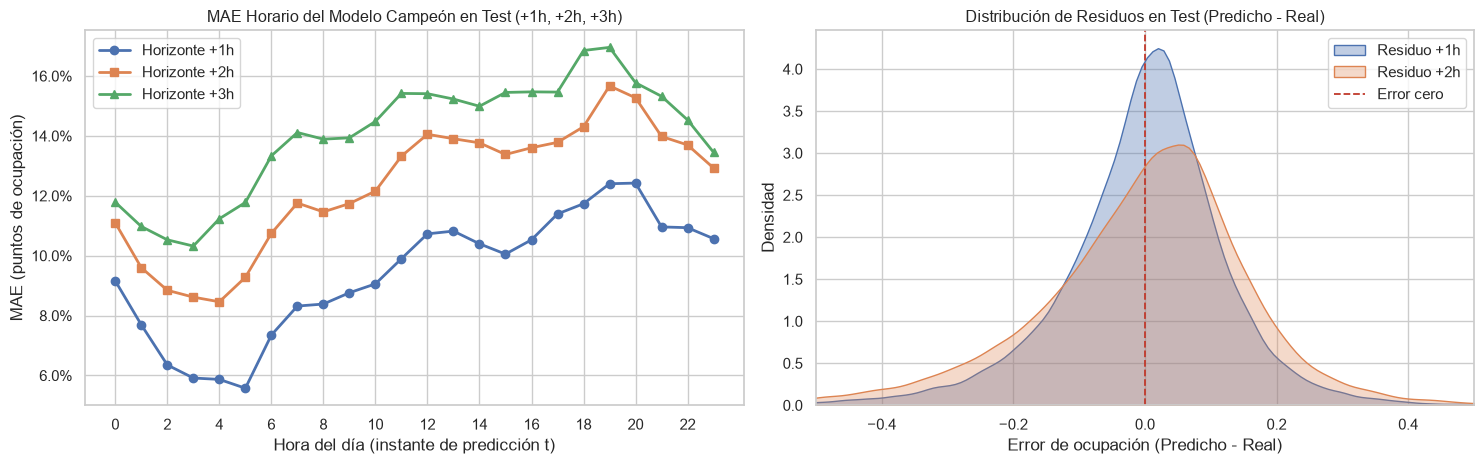

--- TOP 5 ESTACIONES CON MAYOR ERROR EN TEST (HORIZONTE TÁCTICO +2H) ---


,station_id,name,capacity,mae_1h,mae_2h,mae_3h,occ_media_test
88,90,108-Emperador Carlos V,18,0.2084,0.2355,0.2413,0.4803
53,55,102-Teatro Romano,23,0.1745,0.2329,0.2334,0.4481
110,113,33-Echegaray: El Pilar,19,0.1747,0.2305,0.2847,0.3465
94,96,114-Hispanidad: Villahermosa,19,0.1503,0.2144,0.2459,0.3573
37,39,30-Pta. Sancho: Gargallo,19,0.1521,0.2051,0.2239,0.5459


--- TOP 5 ESTACIONES CON MENOR ERROR EN TEST (HORIZONTE TÁCTICO +2H) ---


,station_id,name,capacity,mae_1h,mae_2h,mae_3h,occ_media_test
248,252,231- Heroínas Sitios: Gómara,19,0.0329,0.0487,0.0625,0.0844
261,265,232- Cañones Zaragoza: Tella,19,0.0391,0.0530,0.0677,0.1606
237,241,200- Pza. Bámbola,19,0.0439,0.0535,0.0657,0.0811
244,248,214- Ciud. Kane: Los Pájaros,19,0.0473,0.0541,0.0552,0.0795
146,149,238-Tomás y Valiente,19,0.0442,0.0544,0.0539,0.1268


In [13]:
# ==============================================================================
# 10.1. EVALUACIÓN FINAL CIEGA SOBRE EL CONJUNTO DE TEST (df_test)
# ==============================================================================
champion_models = trained_models_val["LightGBM"]
resultados_test = []
test_predictions_df = df_test[["station_id", "name", "timestamp", "hour", "day_type_effective", "capacity", "occupancy_pct"]].copy()

for h in HORIZONS_HOURS:
    target_col = f"target_occ_{h}h"
    feat_cols = get_features_for_horizon(h)
    y_te = df_test[target_col]

    # 1. Baseline Persistencia (Naive) en Test
    pred_naive_te = df_test["occupancy_pct"].to_numpy()
    res_naive = evaluar_prediccion("Baseline 1: Persistencia (Naive)", h, y_te, pred_naive_te, registrar=False)
    resultados_test.append(res_naive)

    # 2. Baseline Regresión Ridge (usando transformador y modelo ajustados en Train)
    prep_lin, ridge_mod = ridge_models[h]
    X_te_lin = prep_lin.transform(df_test[feat_cols])
    pred_ridge_te = ridge_mod.predict(X_te_lin)
    res_ridge = evaluar_prediccion("Baseline 3: Regresión Ridge", h, y_te, pred_ridge_te, registrar=False)
    resultados_test.append(res_ridge)

    # 3. Modelo Campeón LightGBM
    _, _, X_te_tree = prepare_tree_datasets(df_train, df_val, df_test, feat_cols)
    pred_lgbm_te = np.clip(champion_models[h].predict(X_te_tree), 0.0, 1.0)
    res_lgbm = evaluar_prediccion("Modelo Campeón: LightGBM", h, y_te, pred_lgbm_te, registrar=False)
    resultados_test.append(res_lgbm)

    # Guardamos verdad real y predicción del campeón para auditoría detallada
    test_predictions_df[target_col] = y_te.to_numpy()
    test_predictions_df[f"pred_lgbm_{h}h"] = pred_lgbm_te
    test_predictions_df[f"abs_err_{h}h"] = np.abs(y_te.to_numpy() - pred_lgbm_te)
    test_predictions_df[f"err_{h}h"] = pred_lgbm_te - y_te.to_numpy()

df_resultados_test = pd.DataFrame(resultados_test).sort_values(["Horizonte", "MAE"]).reset_index(drop=True)
print("--- RESULTADOS FINALES EN TEST (EVALUACIÓN CIEGA OUT-OF-TIME) ---")
display(df_resultados_test)

# ==============================================================================
# 10.2. AUDITORÍA DE ERRORES POR FRANJA HORARIA Y TIPO DE DÍA (TEST)
# ==============================================================================
err_horario = (
    test_predictions_df.groupby(["day_type_effective", "hour"], as_index=False)
    .agg(
        mae_1h=("abs_err_1h", "mean"),
        mae_2h=("abs_err_2h", "mean"),
        mae_3h=("abs_err_3h", "mean"),
        sesgo_1h=("err_1h", "mean"),
    )
)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# Gráfico 1: MAE horario en Test para los 3 horizontes (global Test)
err_hora_global = (
    test_predictions_df.groupby("hour", as_index=False)[["abs_err_1h", "abs_err_2h", "abs_err_3h"]].mean()
)
axes[0].plot(err_hora_global["hour"], err_hora_global["abs_err_1h"], marker="o", linewidth=2, label="Horizonte +1h")
axes[0].plot(err_hora_global["hour"], err_hora_global["abs_err_2h"], marker="s", linewidth=2, label="Horizonte +2h")
axes[0].plot(err_hora_global["hour"], err_hora_global["abs_err_3h"], marker="^", linewidth=2, label="Horizonte +3h")
axes[0].set_title("MAE Horario del Modelo Campeón en Test (+1h, +2h, +3h)", fontsize=11.5)
axes[0].set_xlabel("Hora del día (instante de predicción t)")
axes[0].set_ylabel("MAE (puntos de ocupación)")
axes[0].set_xticks(range(0, 24, 2))
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[0].legend()

# Gráfico 2: Distribución de residuos (Predicho - Real) en +1h y +2h
sns.kdeplot(test_predictions_df["err_1h"], fill=True, alpha=0.35, label="Residuo +1h", ax=axes[1])
sns.kdeplot(test_predictions_df["err_2h"], fill=True, alpha=0.30, label="Residuo +2h", ax=axes[1])
axes[1].axvline(0.0, color="#c0392b", linestyle="--", linewidth=1.3, label="Error cero")
axes[1].set_title("Distribución de Residuos en Test (Predicho - Real)", fontsize=11.5)
axes[1].set_xlabel("Error de ocupación (Predicho - Real)")
axes[1].set_ylabel("Densidad")
axes[1].set_xlim(-0.5, 0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

# ==============================================================================
# 10.3. AUDITORÍA ESPACIAL: TOP 5 ESTACIONES CON MAYOR Y MENOR ERROR (+2H TÁCTICO)
# ==============================================================================
err_estacion = (
    test_predictions_df.groupby(["station_id", "name", "capacity"], as_index=False)
    .agg(
        mae_1h=("abs_err_1h", "mean"),
        mae_2h=("abs_err_2h", "mean"),
        mae_3h=("abs_err_3h", "mean"),
        occ_media_test=("occupancy_pct", "mean"),
    )
)

print("--- TOP 5 ESTACIONES CON MAYOR ERROR EN TEST (HORIZONTE TÁCTICO +2H) ---")
display(err_estacion.sort_values("mae_2h", ascending=False).head(5).round(4))

print("--- TOP 5 ESTACIONES CON MENOR ERROR EN TEST (HORIZONTE TÁCTICO +2H) ---")
display(err_estacion.sort_values("mae_2h", ascending=True).head(5).round(4))

> ### 💡 Conclusiones de la Evaluación Ciega en Test (`df_test`) y Auditoría de Errores
>
> 1. **Generalización robusta ante cambio de régimen semanal (`WEEKEND` al 85,42 %):**
>    * **Horizonte $+1\text{ h}$:** Aunque en un fin de semana tranquilo la Persistencia (*Naive*) marca un MAE ligeramente inferior (**0,0916** vs. **0,0938**), **LightGBM** logra el menor error cuadrático (**RMSE = 0,1296** frente a **0,1402**), la mayor varianza explicada (**$R^2 = 0,7259$** frente a **0,6792**) y el mejor **Recall de estaciones vacías (0,8277)**, evitando errores graves en picos de demanda.
>    * **Horizontes tácticos $+2\text{ h}$ y $+3\text{ h}$:** **LightGBM** domina todas las métricas continuas y de detección de vaciado: en **$+2\text{ h}$** alcanza **MAE = 0,1230** y **$R^2 = 0,5594$** (frente a **0,4021** de Naive y **0,4988** de Ridge); en **$+3\text{ h}$** mantiene **MAE = 0,1402** y **$R^2 = 0,4464$** (frente a **0,1612** de Naive y **0,3424** de Ridge), conservando un **F1 Vacía de 0,6845** mientras Ridge colapsa en saturación (**F1 Saturada = 0,0000**).
>
> 2. **Patrón horario del error y distribución de residuos:**
>    * **Ciclo intradía del MAE:** El error alcanza su mínimo de madrugada entre las **03:00 y las 05:00** (**~5,6 %** en $+1\text{ h}$, **~8,4 %** en $+2\text{ h}$ y **~10,3 %** en $+3\text{ h}$) y repunta progresivamente durante la actividad vespertina hasta marcar su máximo a las **19:00–20:00** (**~12,4 %** en $+1\text{ h}$, **~15,7 %** en $+2\text{ h}$ y **~17,0 %** en $+3\text{ h}$), reflejando la mayor variabilidad del ocio y retorno en fin de semana.
>    * **Centrado de residuos:** La distribución de errores ($\hat{y} - y$) se mantiene simétrica y centrada en torno a cero, con un levísimo sesgo positivo (+0,01 a +0,03) coherente con la transición de *Train* (mayormente laborable) a *Test* (fin de semana).
>
> 3. **Contraste espacial por estación en el horizonte táctico $+2\text{ h}$:**
>    * **Estaciones con mayor error (`MAE` ~0,20–0,24):** Se concentran en nodos turísticos, céntricos y de alta rotación con ocupaciones medias elevadas (35 %–55 %), como `108-Emperador Carlos V` (**MAE = 0,2355**), `102-Teatro Romano` (**0,2329**), `33-Echegaray: El Pilar` (**0,2305**), `114-Hispanidad: Villahermosa` (**0,2144**) y `30-Pta. Sancho: Gargallo` (**0,2051**).
>    * **Estaciones con menor error (`MAE` ~0,049–0,054):** Corresponden a estaciones periféricas de baja variabilidad como `231-Heroínas Sitios: Gómara` (**MAE = 0,0487**), `232-Cañones Zaragoza: Tella` (**0,0530**), `200-Pza. Bámbola` (**0,0535**), `214-Ciud. Kane: Los Pájaros` (**0,0541**) y `238-Tomás y Valiente` (**0,0544**).

---
## 11. Explicabilidad del Modelo Campeón (SHAP)

Para cerrar la fase de experimentación y validar que el modelo aprende relaciones físicas coherentes antes de migrar el código a `src/modeling/` y `scripts/`, analizamos la explicabilidad global de **LightGBM** mediante valores **SHAP (`TreeExplainer`)** sobre una muestra representativa de **5.000 observaciones de `df_test`** en el horizonte táctico principal ($+2\text{ h}$).

Este diagnóstico permite auditar el peso relativo de la inercia reciente, la velocidad de llenado/vaciado, la hora objetivo y la identidad espacial de cada estación en las predicciones del sistema.

--- TOP 12 VARIABLES MÁS INFLUYENTES SEGÚN SHAP (HORIZONTE +2H) ---


,Feature,Mean_Abs_SHAP
0,occupancy_pct,0.0998
1,station_id_cat,0.0441
2,hour_cos,0.0131
3,bikes_available,0.0122
4,target_hour_cos_2h,0.0107
5,dow_sin,0.0089
6,target_hour_sin_2h,0.0084
7,hour_sin,0.0081
8,anchors_free,0.0060
9,delta_occ_1h,0.0053


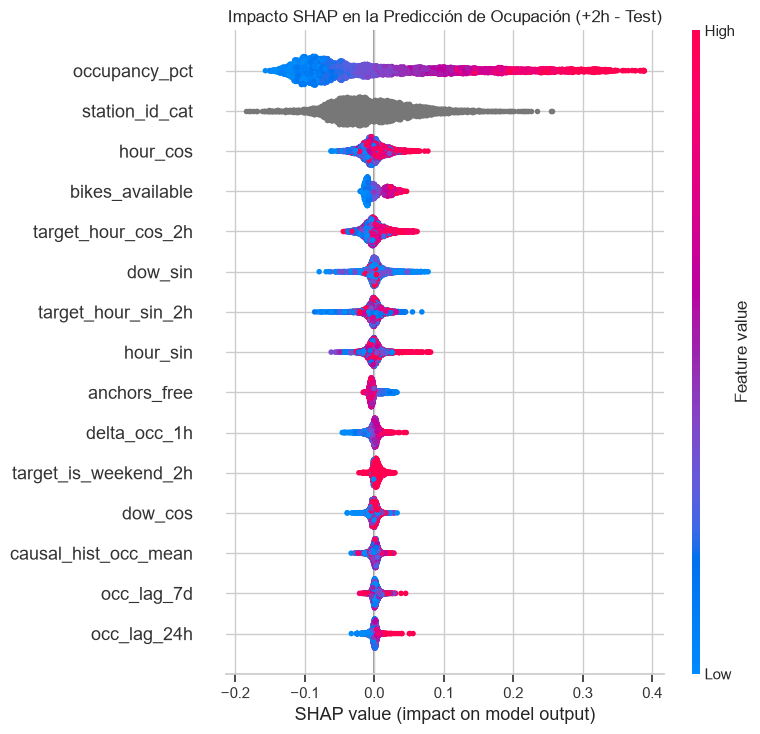

In [14]:
# ==============================================================================
# 11.1. EXPLICABILIDAD GLOBAL MEDIANTE SHAP (HORIZONTE TÁCTICO +2H EN TEST)
# ==============================================================================
h_explain = 2
feat_cols_2h = get_features_for_horizon(h_explain)
_, _, X_te_tree_2h = prepare_tree_datasets(df_train, df_val, df_test, feat_cols_2h)

# Muestra aleatoria reproducible de 5.000 registros de Test para cálculo rápido de SHAP
sample_idx = X_te_tree_2h.sample(n=min(5000, len(X_te_tree_2h)), random_state=RANDOM_STATE).index
X_shap_sample = X_te_tree_2h.loc[sample_idx].copy()

explainer = shap.TreeExplainer(champion_models[h_explain])
shap_values = explainer.shap_values(X_shap_sample)

# Importancia global media |SHAP|
shap_importance = (
    pd.DataFrame({
        "Feature": feat_cols_2h,
        "Mean_Abs_SHAP": np.abs(shap_values).mean(axis=0),
    })
    .sort_values("Mean_Abs_SHAP", ascending=False)
    .reset_index(drop=True)
)

print(f"--- TOP 12 VARIABLES MÁS INFLUYENTES SEGÚN SHAP (HORIZONTE +{h_explain}H) ---")
display(shap_importance.head(12).round(5))

# Gráfico SHAP Summary (Beeswarm) de las 15 principales variables
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values,
    X_shap_sample,
    max_display=15,
    show=False,
)
plt.title(f"Impacto SHAP en la Predicción de Ocupación (+{h_explain}h - Test)", fontsize=12)
plt.tight_layout()
plt.show()

> ### 💡 Conclusiones de Explicabilidad Global (SHAP — Horizonte Táctico $+2\text{ h}$)
>
> * **Predominio de la inercia actual y la firma espacial:** El estado presente de la estación (`occupancy_pct`, con $|\text{SHAP}| = 0,0998$) y su identidad geográfica/operativa (`station_id_cat`, con $0,0441$) concentran el mayor peso explicativo. El diagrama *beeswarm* confirma una relación monótona limpia: ocupaciones actuales altas (puntos rojos) empujan la predicción futura al alza hasta $+0,39$ puntos, mientras que ocupaciones bajas (puntos azules) la desplazan hacia abajo.
> * **Capacidad del modelo para anticipar el cambio de ciclo horario:** Las variables cíclicas tanto del instante actual (`hour_cos = 0,0131`, `hour_sin = 0,0081`) como de la hora objetivo futura (`target_hour_cos_2h = 0,0107`, `target_hour_sin_2h = 0,0084`) y del día de la semana (`dow_sin = 0,0089`, `target_is_weekend_2h = 0,0047`) ocupan las siguientes posiciones, permitiendo corregir la inercia cuando se aproxima una hora punta o un cambio de régimen entre laborable y fin de semana.
> * **Aporte de la dinámica reciente y la memoria histórica:** La velocidad de cambio en la última hora (`delta_occ_1h = 0,0053`), los anclajes libres (`anchors_free = 0,0060`), el perfil basal causal (`causal_hist_occ_mean`) y los retardos de 24 horas y 7 días (`occ_lag_24h`, `occ_lag_7d`) refinan el ajuste fino en estaciones de alta rotación.

---

## 12. Exportación de Predicciones para el Motor de Optimización de Rutas

Para desacoplar la inferencia de Machine Learning del motor prescriptivo (`notebooks/optimizacion_rutas.ipynb`) y garantizar que las simulaciones de rutas sean **100 % deterministas y reproducibles**, persistimos en disco las predicciones *out-of-sample* del modelo campeón (**LightGBM**) sobre el conjunto de prueba (`df_test`).

### Contrato de datos y aislamiento en el *snapshot*
* **Ubicación:** `data/gold_snapshot_ml_20261115/predictions/test_predictions_lgbm.parquet` (aislado en la subcarpeta `predictions/` para mantener intactas las tablas originales de la Capa Gold).
* **Garantía *anti-leakage*:** Al exportar exclusivamente `df_test`, el optimizador de rutas operará sobre jornadas inéditas para el modelo.
* **Esquema exportado:**
  * **Claves espacio-temporales:** `station_id`, `timestamp` (para seleccionar cualquier instante de corte $t_0$).
  * **Estado físico observado en $t$:** `occupancy_pct`, `bikes_available`, `anchors_free` (necesarios para el modo reactivo $\tau_{\text{mode}} = 0$ y las restricciones físicas de cada estación).
  * **Pronósticos multi-horizonte recortados a $[0, 1]$:** `pred_lgbm_1h`, `pred_lgbm_2h`, `pred_lgbm_3h` (necesarios para calcular la ocupación efectiva híbrida $y_s^{\text{eff}}(\tau_{\text{mode}})$).
  * **Contexto temporal básico:** `hour`, `day_type_effective`.

In [15]:
# ==============================================================================
# 12.1. EXPORTACIÓN DETERMINISTA DE PREDICCIONES EN TEST PARA RUTAS (VRP)
# ==============================================================================
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)

# Construimos la tabla puente alineada índice a índice con df_test
df_export_pred = df_test[
    [
        "station_id",
        "timestamp",
        "hour",
        "day_type_effective",
        "occupancy_pct",
        "bikes_available",
        "anchors_free",
    ]
].copy()

# Extraemos los pronósticos de LightGBM desde test_predictions_df y acotamos a [0, 1]
for h in HORIZONS_HOURS:
    if f"pred_lgbm_{h}h" in test_predictions_df.columns:
        raw_pred = test_predictions_df[f"pred_lgbm_{h}h"].to_numpy()
    elif f"pred_{h}h" in test_predictions_df.columns:
        raw_pred = test_predictions_df[f"pred_{h}h"].to_numpy()
    else:
        raise KeyError(
            f"No se encontró la columna de predicción para +{h}h en test_predictions_df. "
            f"Columnas disponibles: {list(test_predictions_df.columns)}"
        )

    df_export_pred[f"pred_lgbm_{h}h"] = np.clip(raw_pred, 0.0, 1.0)

# Ordenamos de forma determinista y guardamos en Parquet
df_export_pred = df_export_pred.sort_values(["timestamp", "station_id"]).reset_index(drop=True)
df_export_pred.to_parquet(PATH_PREDICTIONS_TEST, index=False)

# Auditoría de integridad del artefacto generado
assert df_export_pred[["pred_lgbm_1h", "pred_lgbm_2h", "pred_lgbm_3h"]].isna().sum().sum() == 0, (
    "Error: existen valores nulos en las predicciones exportadas."
)

print("--- EXPORTACIÓN COMPLETADA PARA EL MOTOR DE OPTIMIZACIÓN DE RUTAS ---")
print(f"Archivo generado : {PATH_PREDICTIONS_TEST.relative_to(ROOT_DIR)}")
print(f"Dimensiones      : {df_export_pred.shape[0]:,} filas x {df_export_pred.shape[1]} columnas")
print(f"Rango temporal   : {df_export_pred['timestamp'].min()} -> {df_export_pred['timestamp'].max()}")
print(f"Estaciones únicas: {df_export_pred['station_id'].nunique()}")
display(df_export_pred.head(5))

--- EXPORTACIÓN COMPLETADA PARA EL MOTOR DE OPTIMIZACIÓN DE RUTAS ---
Archivo generado : data\gold_snapshot_ml_20261115\predictions\test_predictions_lgbm.parquet
Dimensiones      : 79,488 filas x 10 columnas
Rango temporal   : 2026-11-13 17:19:59+01:00 -> 2026-11-15 16:47:57+01:00
Estaciones únicas: 276


,station_id,timestamp,hour,day_type_effective,occupancy_pct,bikes_available,anchors_free,pred_lgbm_1h,pred_lgbm_2h,pred_lgbm_3h
0,2,2026-11-13 17:19:59+01:00,17,WEEKDAY,0.4211,8,10,0.3531,0.3510,0.2847
1,3,2026-11-13 17:19:59+01:00,17,WEEKDAY,0.7368,14,3,0.5622,0.3454,0.3567
2,4,2026-11-13 17:19:59+01:00,17,WEEKDAY,0.0000,0,18,0.1517,0.3852,0.3682
3,5,2026-11-13 17:19:59+01:00,17,WEEKDAY,0.1053,2,16,0.2052,0.1869,0.1829
4,6,2026-11-13 17:19:59+01:00,17,WEEKDAY,0.0526,1,15,0.2767,0.4623,0.5006


---

## 13. Síntesis Ejecutiva y Hoja de Ruta de Producción (`src/modeling/`)

### Resumen de hallazgos clave del experimento
1. **Calidad e integridad de datos (*Anti-Leakage*):** Partiendo de **540.960 registros 100 % reales (`is_estimated == 0`)** en **276 estaciones**, se construyeron **530.748 muestras multi-horizonte** ($+1\text{ h}, +2\text{ h}, +3\text{ h}$) con partición cronológica estricta (`70 % Train / 15 % Validación / 15 % Test`) aislada mediante ventanas de embargo de $3\text{ horas}$.
2. **Arquitectura ganadora validada (`LightGBMRegressor`):** En la evaluación ciega sobre *Test*, **LightGBM** supera a la Persistencia (*Naive*) y a la Regresión Ridge en varianza explicada en todos los plazos (**$R^2 = 0,7259$** en $+1\text{ h}$, **$R^2 = 0,5594$** en $+2\text{ h}$ y **$R^2 = 0,4464$** en $+3\text{ h}$), reduciendo el error medio en horizontes tácticos hasta **MAE = 0,1230 ($+2\text{ h}$)** y **MAE = 0,1402 ($+3\text{ h}$)** y manteniendo un **Recall de estaciones vacías superior al 82 %** a $+1\text{ h}$.
3. **Escalabilidad garantizada a $>1\text{ mes}$ de histórico:** Tanto la ingeniería de características (`occ_lag_7d`, `causal_hist_occ_mean`) como el entrenamiento con LightGBM (~11–13 s por horizonte) están preparados para absorber el histórico completo superior a 30 días sin cambios estructurales.

### Próximos pasos de ingeniería del proyecto
* **Acoplamiento inmediato para Investigación Operativa (`notebooks/optimizacion_rutas.ipynb`):** El artefacto puente `data/gold_snapshot_ml_20261115/predictions/test_predictions_lgbm.parquet` exportado en la Sección 12 deja listas las predicciones *out-of-sample* ($\hat{y}_{s, t+h}$) para prototipar y validar de forma reproducible el motor prescriptivo de rutas (6 furgonetas, 22 huecos de capacidad).
* **Modularización en `src/modeling/`:** Trasladar las funciones validadas de este cuaderno a `src/modeling/features.py` (construcción de retardos, perfiles causales y variables cíclicas) y `src/modeling/train.py` (entrenamiento, validación y evaluación multi-horizonte).
* **Orquestación desde `scripts/`:** Crear el script ejecutable de entrenamiento e inferencia que genere los modelos serializados y la matriz de ocupaciones esperadas en producción.